# Как искать динамику по данным: пример с роботами

В круглой арене движутся и вращаются 30 роботов. По записи их положений и ориентаций проверим, какие зависимости может найти EPDE. Сначала разберём вращение одного робота, затем его перемещение: помогают ли контакты с соседями и стеной объяснить его на новых данных. В конце опишем рой целиком через поля плотности и поляризации.

Поиск идёт в слабой постановке EPDE на закреплённой версии библиотеки. Это пример подхода на чужих данных: выбор переменных, функций и проверок здесь следует из устройства этого процесса.

Инструкция по установке лежит рядом с ноутбуком. Для чтения достаточно сохранённых результатов. Запуск всех ячеек занимает меньше минуты и по умолчанию не повторяет поиск EPDE.

## 1. Данные и гипотеза

### Паспорт данных

Запись получена в лаборатории робототехники ИТМО

Используем запись с 30 роботами: 8250 кадров, 25 кадров в секунду, шаг 0,04 с, всего 330 секунд. Половина роботов вращается по часовой стрелке, половина против. Диаметр арены 41 см.

| Величина | Что содержит | Единицы | Размер |
|---|---|---|---|
| $t$ | Время от начала записи | с | 8250 |
| $x, y$ | Координаты центров роботов на изображении, ось $y$ направлена вниз | пиксели | 8250 × 30 |
| $\phi$ | Ориентация робота после разворачивания угла | рад | 8250 × 30 |

Строка соответствует кадру, столбец — роботу. Номер робота не равен номеру столбца. В исходной записи угол задан в градусах и прыгает при полном обороте; при загрузке он переводится в радианы и разворачивается, иначе скачки дали бы ложные пики производной.

**Участки.** Поиск идёт только на первых 60 секундах. Интервал 60–120 с откладываем для проверки: он не участвует ни в подготовке признаков, ни в поиске.

In [1]:
import json, os, random, re, subprocess, sys, time
from contextlib import redirect_stderr, redirect_stdout
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[key] = '1'

# Папка ноутбука; результаты поиска лежат рядом с ним.
HERE = Path.cwd()
if not (HERE / 'robot_reference.ipynb').exists():
    HERE = HERE / 'cases' / 'robots'
# Клон EPDE: по умолчанию в папке vendor в корне репозитория, иначе путь из EPDE_ROOT.
EPDE_PATH = Path(os.environ.get('EPDE_ROOT', HERE.parents[1] / 'vendor' / 'EPDE')).resolve()

PIN = '48e3789aedb9a316b9a5cee78e0c8f96e9f196ba'
RECORDING = 'N30_PWM10_D41'
FPS = 25
TRAIN_END = 60.0   # обучающий участок, секунды
TEST_END = 120.0   # конец отложенного участка, секунды
MAIN_ROBOT = 72    # почти не подходит к стене на обучающем участке
WALL_ROBOT = 38    # почти всё время у стены


def epde_root():
    """Путь к клону EPDE; коммит должен совпадать с закреплённым."""
    head = subprocess.check_output(['git', '-C', str(EPDE_PATH), 'rev-parse', 'HEAD'], text=True).strip()
    if head != PIN:
        raise RuntimeError(f'Клон EPDE должен быть на коммите {PIN}, сейчас {head}')
    for path in (EPDE_PATH / 'projects' / 'robot', EPDE_PATH):
        if str(path) not in sys.path:
            sys.path.insert(0, str(path))
    return EPDE_PATH


def load_recording():
    """Время, координаты в пикселях, развёрнутые углы и номера роботов."""
    epde_root()
    from swarm_data import load_swarm, swarm_files, swarm_meta
    path = next(p for p in swarm_files() if swarm_meta(p)['tag'] == RECORDING)
    return load_swarm(path)


def forward_average(values, lag):
    """Среднее по отрезку из lag интервалов на равномерной сетке."""
    integral = np.concatenate((np.zeros_like(values[:1]), np.cumsum((values[1:] + values[:-1]) / 2, axis=0)))
    return (integral[lag:] - integral[:-lag]) / lag


def forward_velocity(values, t, lag):
    """Скорость по прямому приращению; строки соответствуют началу приращения."""
    dt = (t[lag:] - t[:-lag]).reshape((-1,) + (1,) * (values.ndim - 1))
    return (values[lag:] - values[:-lag]) / dt


def scores(truth, prediction):
    """WAPE и доля объяснённой дисперсии на одном участке."""
    error = truth - prediction
    return dict(wape=float(np.abs(error).sum() / np.abs(truth).sum()),
                r2=float(1 - (error ** 2).sum() / ((truth - truth.mean()) ** 2).sum()))


epde_root()
t, x, y, phi, ids = load_recording()

assert x.shape == y.shape == phi.shape == (len(t), len(ids))
assert np.isfinite(x).all() and np.isfinite(y).all() and np.isfinite(phi).all()
assert np.allclose(np.diff(t), 1 / FPS)
print('Кадров и роботов:', x.shape)
print('Время, с:', t[0], '...', t[-1])
print('Пропусков:', int(np.isnan(x).sum() + np.isnan(y).sum() + np.isnan(phi).sum()))

Кадров и роботов: (8250, 30)
Время, с: 0.0 ... 329.96
Пропусков: 0


### Гипотезы

Заранее зафиксируем, какой результат будем считать подтверждением. Результаты разобраны в разделе 6.

| | Гипотеза | Поддержит | Заставит пересмотреть |
|---|---|---|---|
| 1 | Робот вращается с постоянной скоростью $\omega$ | Форма линейного вращения повторяется по сидам, $\omega$ совпадает с наклоном угла, невязка не растёт на отложенном участке | Другая форма уравнений или заметный рост ошибки |
| 2 | Смещение зависит от ориентации: робот сам толкает себя в направлении, связанном с $\phi$ | Уравнение с ориентацией лучше нулевой скорости на отложенном участке | Нет выигрыша у нулевой скорости |
| 3 | Соседи отталкивают робота при контакте | Член толчка с положительным знаком на фронте в разных сидах и улучшение на отложенном участке | Знак меняется или выигрыша нет |
| 4 | Стена отталкивает робота внутрь арены | То же для члена стены и у типичного робота, и у робота, живущего у стены | Знак меняется или выигрыша нет |
| 5 | На уровне роя плотность переносится поляризацией и расплывается, а поляризация затухает и поворачивается из-за вращения роботов | Эти члены находятся в уравнениях полей с ожидаемыми знаками и работают на новых данных | Другие члены или нет выигрыша на новых данных |

## 2. Подготовка данных

### Посмотреть на измерения и выбрать робота

Перед поиском посмотрим на траектории, угол и на то, сколько времени каждый робот проводит у стены. От этого зависит, что вообще можно узнать по одному роботу.

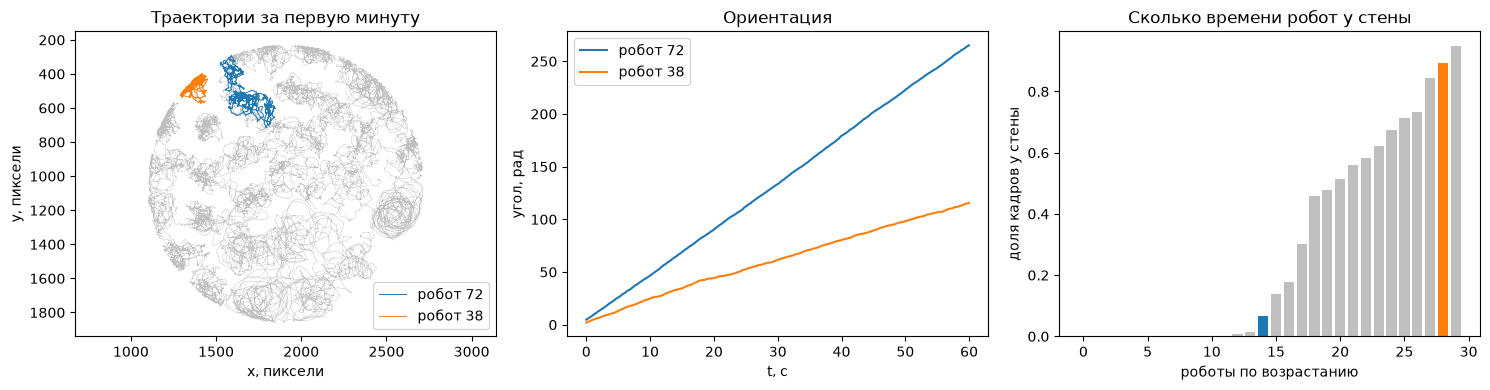

Доля кадров у стены: медиана 0.10, робот 72: 0.07, робот 38: 0.89
Доля кадров в контакте с соседом: медиана 0.87, робот 72: 0.96, робот 38: 0.94


In [2]:
from swarm_data import arena_envelope, contact_features, spin_rates

train = t < TRAIN_END
xc, yc, radius = arena_envelope(x[train], y[train])
contacts = contact_features(x[train], y[train], spin_rates(t[train], phi[train]), xc, yc, radius)
wall_share = (contacts['wall_x'] != 0).mean(axis=0)
contact_share = (contacts['n_contact'] > 0).mean(axis=0)
main, wall = list(ids).index(MAIN_ROBOT), list(ids).index(WALL_ROBOT)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j in range(len(ids)):
    ax[0].plot(x[train, j], y[train, j], lw=.3, color='0.75')
ax[0].plot(x[train, main], y[train, main], lw=.7, label=f'робот {MAIN_ROBOT}')
ax[0].plot(x[train, wall], y[train, wall], lw=.7, label=f'робот {WALL_ROBOT}')
ax[0].set(xlabel='x, пиксели', ylabel='y, пиксели', title='Траектории за первую минуту')
ax[0].invert_yaxis(); ax[0].axis('equal'); ax[0].legend()
ax[1].plot(t[train], phi[train, main], label=f'робот {MAIN_ROBOT}')
ax[1].plot(t[train], phi[train, wall], label=f'робот {WALL_ROBOT}')
ax[1].set(xlabel='t, с', ylabel='угол, рад', title='Ориентация'); ax[1].legend()
order = np.argsort(wall_share)
colors = ['C0' if ids[j] == MAIN_ROBOT else 'C1' if ids[j] == WALL_ROBOT else '0.75' for j in order]
ax[2].bar(range(len(ids)), wall_share[order], color=colors)
ax[2].set(xlabel='роботы по возрастанию', ylabel='доля кадров у стены', title='Сколько времени робот у стены')
plt.tight_layout(); plt.show()

print(f'Доля кадров у стены: медиана {np.median(wall_share):.2f}, '
      f'робот {MAIN_ROBOT}: {wall_share[main]:.2f}, робот {WALL_ROBOT}: {wall_share[wall]:.2f}')
print(f'Доля кадров в контакте с соседом: медиана {np.median(contact_share):.2f}, '
      f'робот {MAIN_ROBOT}: {contact_share[main]:.2f}, робот {WALL_ROBOT}: {contact_share[wall]:.2f}')

Угол растёт почти по прямой, но у разных роботов с разной скоростью. Это основание проверить постоянную скорость вращения. Для перемещения такого вывода сделать нельзя: траектории выглядят случайными.

Роботы сильно различаются. Почти половина за эту минуту стены не касается, а другие стоят у неё большую часть времени; медиана около 10%. По роботу у стены нельзя судить об обычном движении, а по роботу в центре — о стене. Поэтому основной робот здесь близкий к медиане, с номером 72 (у стены 7% кадров), а для сравнения возьмём робота 38, который у стены 89% кадров.

### Шум и производные

Уравнение строится на производных, поэтому сначала проверим, что они показывают.

"лаг, кадры","лаг, с","СКО скорости, см/с"
1,0.04,2.57
2,0.08,2.34
5,0.20,1.97
10,0.40,1.60
20,0.80,1.13
40,1.60,0.65


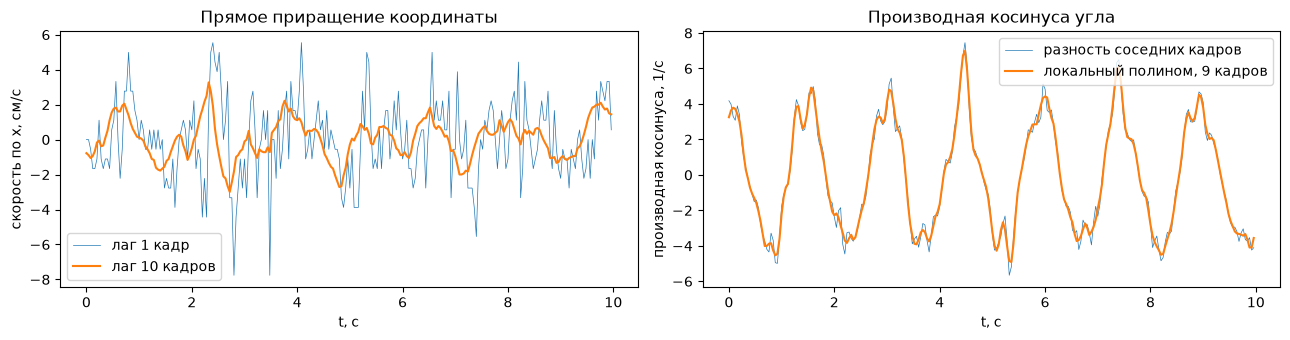

Шаг угла между кадрами при средней скорости, рад: 0.175


In [3]:
from scipy.signal import savgol_filter

import swarm_sim

scale_px = swarm_sim.px_per_cm()
X_main = (x[:, main] - xc) / scale_px
rows = []
for lag in (1, 2, 5, 10, 20, 40):
    velocity = forward_velocity(X_main[train], t[train], lag)
    rows.append({'лаг, кадры': lag, 'лаг, с': lag / FPS, 'СКО скорости, см/с': velocity.std()})
display(pd.DataFrame(rows).style.hide(axis='index').format(precision=2))

c = np.cos(phi[train, main])
plain = np.gradient(c, t[train])
smooth = savgol_filter(c, 9, 3, deriv=1, delta=1 / FPS)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
piece = t[train] < 10
for lag, width, label in ((1, .5, 'лаг 1 кадр'), (10, 1.5, 'лаг 10 кадров')):
    velocity = forward_velocity(X_main[train], t[train], lag)
    ax[0].plot(t[train][:len(velocity)][piece[:len(velocity)]], velocity[piece[:len(velocity)]], lw=width, label=label)
ax[0].set(xlabel='t, с', ylabel='скорость по x, см/с', title='Прямое приращение координаты'); ax[0].legend()
ax[1].plot(t[train][piece], plain[piece], lw=.5, label='разность соседних кадров')
ax[1].plot(t[train][piece], smooth[piece], label='локальный полином, 9 кадров')
ax[1].set(xlabel='t, с', ylabel='производная косинуса, 1/с', title='Производная косинуса угла'); ax[1].legend()
plt.tight_layout(); plt.show()
print('Шаг угла между кадрами при средней скорости, рад:', round(np.polyfit(t[train], phi[train, main], 1)[0] / FPS, 3))

**Перемещение.** Разброс скорости падает с ростом лага заметно медленнее, чем при чисто измерительном шуме: тогда при лаге в 40 раз больше он упал бы примерно в 40 раз, а падает примерно в 4 раза. Значит, большая часть разброса на коротких шагах относится к настоящему движению робота, и сглаживать его как шум нельзя. Поэтому скорость будем понимать как прямое приращение за лаг $L$:

$$
\frac{u(t+L\Delta t)-u(t)}{L\Delta t}, \qquad L=10,\ \ L\Delta t=0{,}4\ \text{с}.
$$

Признаки берутся в начале приращения, то есть не заглядывают в будущее. Прямое приращение также позволяет увидеть снос случайного движения, который симметричная производная усредняет. Выбор лага проверим в разделе 4.

**Слабая постановка.** На правом графике видно, что разность соседних кадров для косинуса угла заметно дрожит. Поэтому производные в каждой точке мы не считаем. Вместо этого EPDE умножает уравнение на гладкую функцию $\psi$, равную нулю на краях окна, и интегрирует по окну. Производная данных при этом переносится на $\psi$:

$$
\int \dot u\,\psi\,dt=-\int u\,\dot\psi\,dt ,
$$

поэтому измеренный сигнал не приходится дифференцировать численно, а шум усредняется внутри окна. Ширину окна EPDE выбирает сам.

Чтобы слабая постановка искала ту же скорость, что и прямое приращение, используем простое тождество: приращение за лаг, делённое на лаг, равно производной среднего значения координаты на отрезке $[t,\,t+L\Delta t]$. Поэтому для перемещения EPDE получает это скользящее среднее, а признаки по-прежнему берутся в начале отрезка.

In [4]:
def prepare_series(t, x, y, phi, ids, robot, end=TEST_END):
    """Величины одного робота от начала записи до end.

    Центр и радиус арены оцениваем только по обучающему участку, чтобы отложенные данные
    не влияли на подготовку признаков. Координаты в сантиметрах, начало в центре арены.
    """
    epde_root()
    import swarm_sim
    from swarm_data import arena_envelope, contact_features, spin_rates
    keep = t < end
    t, x, y, phi = t[keep], x[keep], y[keep], phi[keep]
    train = t < TRAIN_END
    xc, yc, radius = arena_envelope(x[train], y[train])
    scale = swarm_sim.px_per_cm()
    contacts = contact_features(x, y, spin_rates(t, phi), xc, yc, radius)
    k = list(ids).index(robot)
    X, Y = (x[:, k] - xc) / scale, (y[:, k] - yc) / scale
    r, alpha = np.hypot(X, Y), np.arctan2(Y, X)
    # Память: скорость за предыдущие 0,4 с. Будущие значения координаты сюда не входят.
    previous_velocity = np.zeros_like(X)
    previous_velocity[10:] = (X[10:] - X[:-10]) / (10 / FPS)
    angle = phi[:, k]
    push_x, push_y = contacts['push_x'][:, k], contacts['push_y'][:, k]
    wall_x, wall_y = contacts['wall_x'][:, k], contacts['wall_y'][:, k]
    return dict(
        t=t, X=X, Y=Y, r=r, alpha=alpha, phi=angle,
        cos_phi=np.cos(angle), sin_phi=np.sin(angle),
        push_x=push_x, wall_x=wall_x, vb_x=previous_velocity,
        # Проекции на радиальное направление: они нужны для уравнения расстояния до центра.
        cos_rel=np.cos(angle - alpha), sin_rel=np.sin(angle - alpha),
        push_r=push_x * np.cos(alpha) + push_y * np.sin(alpha),
        wall_r=wall_x * np.cos(alpha) + wall_y * np.sin(alpha),
    )

Радиус области центров роботов, см: 17.67


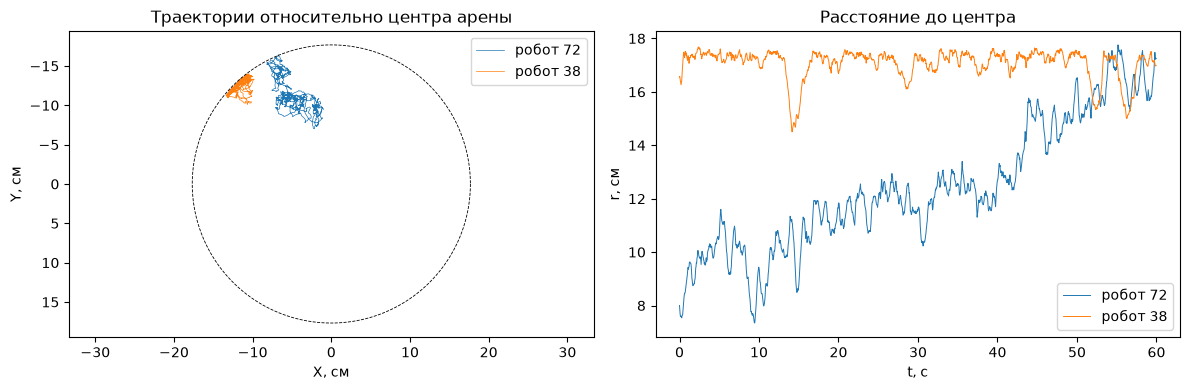

In [5]:
series = {robot: prepare_series(t, x, y, phi, ids, robot) for robot in (MAIN_ROBOT, WALL_ROBOT)}
for s in series.values():
    assert np.allclose(s['X'], s['r'] * np.cos(s['alpha'])) and np.allclose(s['Y'], s['r'] * np.sin(s['alpha']))
print('Радиус области центров роботов, см:', round(radius / scale_px, 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for robot, s in series.items():
    part = s['t'] < TRAIN_END
    ax[0].plot(s['X'][part], s['Y'][part], lw=.5, label=f'робот {robot}')
    ax[1].plot(s['t'][part], s['r'][part], lw=.7, label=f'робот {robot}')
circle = np.linspace(0, 2 * np.pi, 200)
ax[0].plot(radius / scale_px * np.cos(circle), radius / scale_px * np.sin(circle), 'k--', lw=.6)
ax[0].axis('equal'); ax[0].invert_yaxis(); ax[0].legend()
ax[0].set(xlabel='X, см', ylabel='Y, см', title='Траектории относительно центра арены')
ax[1].set(xlabel='t, с', ylabel='r, см', title='Расстояние до центра'); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Конфигурация поиска

### Какие функции даём EPDE

Токен в EPDE — функция, из которой алгоритм может собрать член уравнения. Если нужной зависимости в библиотеке нет, увеличение числа запусков её не добавит.

**Вращение.** Сам угол не подходит: уравнение $\phi'=\omega$ не содержит других переменных, и искать в нём нечего. Перейдём к косинусу и синусу. Если скорость постоянна,

$$
c=\cos\phi,\quad s=\sin\phi \quad\Rightarrow\quad c'=-\omega s,\qquad s'=\omega c .
$$

Это замкнутая система двух уравнений: EPDE ищет обе переменные сразу, и дополнительных токенов не нужно. Сначала библиотека узкая (первая производная, один множитель в члене), затем расширенная (вторая производная, вторая степень, два множителя).

**Перемещение.** Ищем скорость по $X$ одного робота. Кроме самой координаты доступны:

- $\cos\phi$ и $\sin\phi$ — связь перемещения с ориентацией;
- толчок $p_x$ — сумма единичных векторов от соседей, которых робот касается, взятая по оси $x$;
- признак стены $w_x$ — единичный вектор к центру, пока робот касается стены, иначе ноль.

Форму признаков задаём мы; EPDE выбирает, какие из них войдут в уравнение, и оценивает коэффициенты. Свои токены передаются функциями, которые возвращают значения признака на сетке данных. Толчок и стена описывают геометрию, а не измеренную силу. Они берутся из записи положений всех роботов, поэтому такое уравнение условное: без измерений соседей смоделировать по нему рой нельзя.

### Окно слабой постановки

Окно EPDE выбирает по данным сам. Если подать всю минуту одной траекторией, на этих данных он выбирает окна длиной в несколько секунд. За это время робот успевает обернуться несколько раз, вращение внутри окна усредняется, и уравнения теряют смысл. Окно не бывает длиннее траектории, поэтому обучающий участок подаём кусками по 1,3 с — чуть меньше одного оборота основного робота. Каждый кусок EPDE считает отдельной траекторией. Как результат зависит от длины куска, проверим в разделе 4.

### Отбор членов

В этой версии EPDE по умолчанию работает универсальный поиск: эволюционный алгоритм NSGA-II сам подбирает состав уравнения. Для сравнения оставим и прежний способ, при котором каждое уравнение отбирает члены разреживанием. Ниже они называются универсальным поиском и прежним отбором членов. Оба варианта сравниваются при одном бюджете.

### Критерии и бюджет

Первый критерий — невязка WAPE, сумма абсолютных ошибок, делённая на сумму абсолютных значений производной. Второй — нестабильность: относительная изменчивость коэффициентов при переоценке. Оба минимизируются.

Узкий поиск вращения выполняется с популяцией 6 на 3 эпохи, поиски перемещения и расширенный поиск вращения — с популяцией 10 на 15 эпох. Для каждой конфигурации используем 5 сидов. Это учебный бюджет: он показывает весь путь за разумное время, но не доказывает, что поиск исчерпан.

Ниже приведены подготовка данных для поиска и весь вызов EPDE, затем таблица конфигураций и расшифровка обозначений, которые встретятся в выводах.

In [6]:
FIELD_STEP = 2       # поля строим через кадр: шаг 0,08 с
FIELD_GRID = 14      # узлов сетки по каждой оси
CAP_CM = 4.87        # диаметр крышки робота, он же ширина сглаживания


def build_fields(t, x, y, phi, ids, end=TEST_END):
    """Плотность и поляризация роя на квадрате, вписанном в арену.

    Каждый робот размазывается гауссианой шириной в диаметр крышки. Плотность — доля площади,
    поляризация — средний вектор ориентации, W — тот же вектор, умноженный на скорость вращения.
    Центр арены и скорости вращения оцениваем только по обучающему участку.
    """
    epde_root()
    import swarm_sim
    from swarm_data import arena_envelope
    keep = t < end
    t, x, y, phi = t[keep], x[keep], y[keep], phi[keep]
    train = t < TRAIN_END
    xc, yc, radius = arena_envelope(x[train], y[train])
    scale = swarm_sim.px_per_cm()
    spin = np.array([np.polyfit(t[train], phi[train, j], 1)[0] for j in range(len(ids))])
    step = slice(None, None, FIELD_STEP)
    X, Y, angle = (x[step] - xc) / scale, (y[step] - yc) / scale, phi[step]
    half = radius / scale / np.sqrt(2)
    g = np.linspace(-half, half, FIELD_GRID)
    kx = np.exp(-(g[None, None, :] - X[:, :, None]) ** 2 / (2 * CAP_CM ** 2))
    ky = np.exp(-(g[None, None, :] - Y[:, :, None]) ** 2 / (2 * CAP_CM ** 2))
    norm = np.pi * (CAP_CM / 2) ** 2 / (2 * np.pi * CAP_CM ** 2)
    field = lambda weight: norm * np.einsum('ti,tix,tiy->txy', weight, kx, ky)
    fields = dict(t=t[step], g=g, axes=(g, g), rho=field(np.ones_like(angle)), Px=field(np.cos(angle)), Py=field(np.sin(angle)),
                  Wx=field(spin * np.cos(angle)), Wy=field(spin * np.sin(angle)))
    d = lambda a, axis: np.gradient(a, g, axis=axis, edge_order=2)
    lap = lambda a: d(d(a, 1), 1) + d(d(a, 2), 2)
    fields.update(rho_x=d(fields['rho'], 1), rho_y=d(fields['rho'], 2), lap_rho=lap(fields['rho']),
                  div_P=d(fields['Px'], 1) + d(fields['Py'], 2),
                  Px_x=d(fields['Px'], 1), Py_y=d(fields['Py'], 2), lap_Px=lap(fields['Px']), lap_Py=lap(fields['Py']))
    return fields


POLAR_RINGS, POLAR_ANGLES = 12, 24


def build_polar_fields(t, x, y, phi, ids, end=TEST_END):
    """Те же поля на полярной сетке: кольца от 2 см до края области центров роботов и углы по кругу.

    Поляризацию раскладываем на радиальную часть (от центра) и угловую (по кругу).
    """
    epde_root()
    import swarm_sim
    from swarm_data import arena_envelope
    keep = t < end
    t, x, y, phi = t[keep], x[keep], y[keep], phi[keep]
    train = t < TRAIN_END
    xc, yc, radius = arena_envelope(x[train], y[train])
    scale = swarm_sim.px_per_cm()
    spin = np.array([np.polyfit(t[train], phi[train, j], 1)[0] for j in range(len(ids))])
    step = slice(None, None, FIELD_STEP)
    X, Y, angle = (x[step] - xc) / scale, (y[step] - yc) / scale, phi[step]
    rings = np.linspace(2.0, radius / scale, POLAR_RINGS)
    angles = np.linspace(-np.pi, np.pi, POLAR_ANGLES, endpoint=False)
    node_x = rings[:, None] * np.cos(angles)[None, :]
    node_y = rings[:, None] * np.sin(angles)[None, :]
    norm = np.pi * (CAP_CM / 2) ** 2 / (2 * np.pi * CAP_CM ** 2)
    out = {name: np.empty((len(X), POLAR_RINGS, POLAR_ANGLES)) for name in ('rho', 'Px', 'Py', 'Wx', 'Wy')}
    for start in range(0, len(X), 200):
        part = slice(start, start + 200)
        kernel = norm * np.exp(-((node_x[None, None] - X[part, :, None, None]) ** 2 +
                                 (node_y[None, None] - Y[part, :, None, None]) ** 2) / (2 * CAP_CM ** 2))
        for name, weight in (('rho', np.ones_like(angle[part])), ('Px', np.cos(angle[part])), ('Py', np.sin(angle[part])),
                             ('Wx', spin * np.cos(angle[part])), ('Wy', spin * np.sin(angle[part]))):
            out[name][part] = np.einsum('ti,tirk->trk', weight, kernel)
    cos_a, sin_a = np.cos(angles)[None, None, :], np.sin(angles)[None, None, :]
    fields = dict(t=t[step], axes=(rings, angles), rho=out['rho'],
                  Pr=out['Px'] * cos_a + out['Py'] * sin_a, Pt=-out['Px'] * sin_a + out['Py'] * cos_a,
                  Wr=out['Wx'] * cos_a + out['Wy'] * sin_a, Wt=-out['Wx'] * sin_a + out['Wy'] * cos_a)
    r = rings[None, :, None]
    dr = lambda a: np.gradient(a, rings, axis=1, edge_order=2)
    dth = lambda a: (np.roll(a, -1, axis=2) - np.roll(a, 1, axis=2)) / (2 * (angles[1] - angles[0]))
    fields.update(rho_r=dr(fields['rho']), Pr_r=dr(fields['Pr']),
                  lap_rho=dr(dr(fields['rho'])) + dr(fields['rho']) / r + dth(dth(fields['rho'])) / r ** 2,
                  div_P=dr(fields['Pr']) + fields['Pr'] / r + dth(fields['Pt']) / r)
    return fields


FIELD_TOKENS = {
    'rho': ('rho_x', 'rho_y', 'lap_rho', 'div_P', 'Px', 'Py'),
    'Px': ('rho', 'rho_x', 'Py', 'Wy', 'Px_x', 'lap_Px'),
    'Py': ('rho', 'rho_y', 'Px', 'Wx', 'Py_y', 'lap_Py'),
}


POLAR_TOKENS = {
    'rho': ('rho_r', 'lap_rho', 'div_P', 'Pr'),
    'Pr': ('rho', 'rho_r', 'Pt', 'Wt', 'Wr', 'Pr_r'),
}

In [7]:
CHUNK_S = 1.3      # длина куска траектории: окно слабой постановки не может быть длиннее


def search_data(config, t, x, y, phi, ids):
    """Переменные поиска и токены на обучающем участке."""
    kind = config['kind']
    if 'field' in kind:
        fields = (build_polar_fields if kind == 'polar_field' else build_fields)(t, x, y, phi, ids)
        times = fields['t']
        axes = fields['axes']
        if kind == 'field_system':
            # Без ограничений: EPDE сам выбирает и производные, и левую часть уравнений.
            variables = {name: fields[name] for name in ('rho', 'Px', 'Py')}
            tokens, orders = {}, (1, 2, 2)
        else:
            var = config['var']
            names = (POLAR_TOKENS if kind == 'polar_field' else FIELD_TOKENS)[var]
            # Производные по пространству подаём как свои токены: тогда у поля остаётся только
            # производная по времени, и EPDE ставит в левую часть именно её.
            variables = {var: fields[var]}
            tokens, orders = {name: fields[name] for name in names}, (1, 0, 0)
    else:
        series = prepare_series(t, x, y, phi, ids, config['robot'])
        times, axes, orders = series['t'], (), (1,)
        if kind == 'heading':
            variables, tokens = {'c': series['cos_phi'], 's': series['sin_phi']}, {}
        else:
            target = series['X'] if kind == 'drift' else series['r']
            variables = {'u': target}
            tokens = {name: series[name] for name in config['tokens']}

    # Прямое приращение за лаг L равно производной среднего по отрезку [t, t + L].
    # Поэтому в слабой постановке ищем уравнение для такого среднего, а признаки берём в начале отрезка.
    lag = config.get('lag', 10)
    if kind != 'heading' and lag > 1 and config.get('average', True):
        variables = {name: forward_average(values, lag) for name, values in variables.items()}
        times = times[:-lag]
        tokens = {name: values[:-lag] for name, values in tokens.items()}
    train = times < TRAIN_END
    return dict(t=times[train], axes=axes, orders=orders,
                variables={name: values[train] for name, values in variables.items()},
                tokens={name: values[train] for name, values in tokens.items()})

In [8]:
def chunk_tokens(arrays, starts):
    """Свои токены: значения признака на сетке каждого куска траектории.

    EPDE передаёт функции координаты сетки; по первому моменту времени находим нужный кусок.
    """
    from epde import CustomTokens
    from epde.evaluators import CustomEvaluator

    def on_chunks(name):
        table = {round(float(start), 6): values for start, values in zip(starts, arrays[name])}

        def evaluate(*coords, power):
            return table[round(float(np.asarray(coords[0]).flat[0]), 6)] ** power

        return evaluate

    return CustomTokens(
        token_type='physical', token_labels=list(arrays),
        evaluator=CustomEvaluator({name: on_chunks(name) for name in arrays}, ['power'], native_vectorized=True),
        params_ranges={'power': (1, 1)}, meaningful=True,
    )


def search_equations(config, data, seed):
    """Один поиск EPDE в слабой постановке на обучающем участке.

    data: время, оси пространства, переменные поиска и свои токены на обучающем участке.
    Участок делим на куски длиной CHUNK_S: каждый кусок — отдельная траектория, поэтому окно,
    которое EPDE выбирает сам, не бывает длиннее куска.
    """
    from epde import EpdeSearch, TrigonometricTokens

    random.seed(seed)
    np.random.seed(seed)
    t, axes = data['t'], data['axes']
    step = t[1] - t[0]
    length = int(round(config.get('chunk', CHUNK_S) / step)) + 1
    pieces = [np.arange(i, i + length) for i in range(0, len(t) - length + 1, length)]

    # Режим 'plain' — универсальный поиск NSGA-II: состав уравнения подбирает эволюция.
    # Режим 'repair' — прежний способ: каждое уравнение само отбирает члены разреживанием.
    mode = config.get('mode', 'plain')
    factors = config.get('factors', 1)
    mode_options = (dict(system_rps_mode='plain', engine='nsga2',
                         # без этого универсальный поиск сам добавляет произведения токенов
                         system_rps_params={'factor_move_probability': 0.0 if factors == 1 else 'auto'})
                    if mode == 'plain' else dict(system_rps_mode='repair'))

    search = EpdeSearch(
        evaluation_form='weak',
        multiobjective_mode=True,
        second_objective='instability',
        instability_metric=config.get('instability', 'cv'),
        discrepancy_metric='wape',
        use_solver=False,
        boundary_width=2,
        population_size=config['population'],
        training_epochs=config['epochs'],
        default_preprocessor_type='FD',
        preprocessor_kwargs={'scheme': 'forward', 'lag': 1},
        verbose_params={'show_iter_idx': False},
        **mode_options,
    )

    trajectories = []
    for key, piece in enumerate(pieces):
        grid = tuple(np.meshgrid(t[piece], *axes, indexing='ij')) if axes else (t[piece],)
        _, domain = search.createDomain(grid, ID=key)
        variables = {name: values[piece] for name, values in data['variables'].items()}
        _, trajectory = search.createTrajectory(variables, domain, cache_id=key)
        trajectories.append(trajectory)

    tokens = []
    if data['tokens']:
        tokens.append(chunk_tokens({name: [values[p] for p in pieces] for name, values in data['tokens'].items()},
                                   [t[p][0] for p in pieces]))
    if 'trig_freq' in config:
        tokens.append(TrigonometricTokens(freq=config['trig_freq'], dimensionality=0, meaningful=True))

    search.fit(
        data=trajectories,
        max_deriv_order=data['orders'] if config.get('deriv', 1) == 1 else tuple(2 for _ in data['orders']),
        data_fun_pow=config.get('power', 1),
        equation_terms_max_number=config['terms'],
        equation_factors_max_number=factors,
        additional_tokens=tokens,
    )
    return search.equations(only_print=False, num=1)[0]


def run(name, seed):
    config = CONFIGS[name]
    t, x, y, phi, ids = load_recording()
    front = search_equations(config, search_data(config, t, x, y, phi, ids), seed)
    rows = []
    for model in front:
        objectives = [float(value) for value in np.ravel(model.obj_fun)]
        if not np.isfinite(objectives).all():
            raise ValueError(f'Нечисловые критерии: {objectives}')
        rows.append(dict(equation=model.text_form.split('\n{')[0], objectives=objectives))
    return dict(config_name=name, seed=seed, config=config, epde_commit=PIN, front=rows)

In [9]:
SMALL = dict(population=6, epochs=3, terms=4)
LARGE = dict(population=10, epochs=15, terms=7)
CONTACTS = ('cos_phi', 'sin_phi', 'push_x', 'wall_x')

# Что считаем и какими средствами. Все конфигурации одного сравнения используют один бюджет.
CONFIGS = {
    # Вращение: система из двух уравнений для косинуса и синуса угла.
    'heading': dict(kind='heading', robot=MAIN_ROBOT, **SMALL),
    'heading_wide': dict(kind='heading', robot=MAIN_ROBOT, **LARGE, deriv=2, power=2, factors=2, chunk=2.6),
    'heading_chunk52': dict(kind='heading', robot=MAIN_ROBOT, **SMALL, chunk=5.2),
    'heading_chunk26': dict(kind='heading', robot=MAIN_ROBOT, **SMALL, chunk=2.6),
    # Перемещение по x: только ориентация, затем контакты при двух способах отбора членов.
    'drift_orientation': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=('cos_phi', 'sin_phi')),
    'drift_repair': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=CONTACTS, mode='repair'),
    'drift': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=CONTACTS),
    'drift_wall_robot': dict(kind='drift', robot=WALL_ROBOT, **LARGE, tokens=CONTACTS),
    # Чувствительность к шагу прямого приращения.
    'drift_lag5': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=CONTACTS, lag=5),
    'drift_lag20': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=CONTACTS, lag=20),
    # Вторая производная координаты.
    'drift_second': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=CONTACTS, deriv=2, chunk=2.6),
    # Другие токены: память скорости, произведения, готовые тригонометрические функции времени.
    'drift_memory': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=(*CONTACTS, 'vb_x')),
    'drift_products': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=CONTACTS, factors=2),
    'drift_trig': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=('push_x', 'wall_x'), trig_freq=(4.0, 4.7)),
    # Другие методы: критерий нестабильности и усреднение за лаг.
    'drift_chi2': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=CONTACTS, instability='chi2'),
    'drift_raw': dict(kind='drift', robot=MAIN_ROBOT, **LARGE, tokens=CONTACTS, average=False),
    # То же перемещение в полярной координате: расстояние до центра арены.
    'radial': dict(kind='radial', robot=MAIN_ROBOT, **LARGE, tokens=('cos_rel', 'sin_rel', 'push_r', 'wall_r')),
    # Уровень роя: поля плотности и поляризации на сетке.
    'field_free': dict(kind='field_system', **SMALL, lag=1),
    'field_rho': dict(kind='field', var='rho', **SMALL, lag=1),
    'field_rho_lag5': dict(kind='field', var='rho', **SMALL, lag=5),
    'field_Px': dict(kind='field', var='Px', **SMALL, lag=1),
    'field_Py': dict(kind='field', var='Py', **SMALL, lag=1),
    # Те же поля в полярных координатах: кольца и углы до самой стены.
    'polar_rho': dict(kind='polar_field', var='rho', **SMALL, lag=5),
    'polar_Pr': dict(kind='polar_field', var='Pr', **SMALL, lag=1),
}


display(pd.DataFrame(CONFIGS).T.fillna('—'))

legend = {
    'c, s': 'косинус и синус угла ориентации',
    'dc/dx0, ds/dx0': 'их производные по времени; индекс 0 в EPDE означает время',
    'u': 'переменная поиска: координата X или расстояние r, см',
    'du/dx0': 'скорость по прямому приращению, см/с',
    'd^2u/dx0^2': 'вторая производная: изменение этой скорости за то же время, см/с²',
    'cos_phi, sin_phi': 'косинус и синус угла ориентации как внешние признаки',
    'push_x, wall_x': 'толчок соседей и признак стены по оси X',
    'vb_x': 'память: скорость за предыдущие 0,4 с, см/с',
    'sin(4.300t), cos(4.300t)': 'готовые функции времени с подобранной частотой',
    'rho, Px, Py': 'поля: плотность роботов и средний вектор их ориентации',
    'Wx, Wy': 'средний вектор ориентации, умноженный на скорость вращения',
    'rho_x, rho_y, Px_x, Py_y': 'производные полей по координатам x и y',
    'div_P, lap_rho, lap_Px, lap_Py': 'дивергенция поляризации и лапласианы полей',
    'dx1, dx2': 'в EPDE это производные по координатам x и y',
    'cos_rel, sin_rel': 'косинус и синус угла между ориентацией и направлением от центра',
    'push_r, wall_r': 'толчок соседей и признак стены вдоль радиуса',
}
display(pd.DataFrame(legend.items(), columns=['обозначение в выводах', 'смысл']).style.hide(axis='index'))

,kind,robot,population,epochs,terms,deriv,power,factors,chunk,tokens,mode,lag,trig_freq,instability,average,var
heading,heading,72,6,3,4,—,—,—,—,—,—,—,—,—,—,—
heading_wide,heading,72,10,15,7,2,2,2,2.6,—,—,—,—,—,—,—
heading_chunk52,heading,72,6,3,4,—,—,—,5.2,—,—,—,—,—,—,—
heading_chunk26,heading,72,6,3,4,—,—,—,2.6,—,—,—,—,—,—,—
drift_orientation,drift,72,10,15,7,—,—,—,—,"(cos_phi, sin_phi)",—,—,—,—,—,—
drift_repair,drift,72,10,15,7,—,—,—,—,"(cos_phi, sin_phi, push_x, wall_x)",repair,—,—,—,—,—
drift,drift,72,10,15,7,—,—,—,—,"(cos_phi, sin_phi, push_x, wall_x)",—,—,—,—,—,—
drift_wall_robot,drift,38,10,15,7,—,—,—,—,"(cos_phi, sin_phi, push_x, wall_x)",—,—,—,—,—,—
drift_lag5,drift,72,10,15,7,—,—,—,—,"(cos_phi, sin_phi, push_x, wall_x)",—,5,—,—,—,—
drift_lag20,drift,72,10,15,7,—,—,—,—,"(cos_phi, sin_phi, push_x, wall_x)",—,20,—,—,—,—


обозначение в выводах,смысл
"c, s",косинус и синус угла ориентации
"dc/dx0, ds/dx0",их производные по времени; индекс 0 в EPDE означает время
u,"переменная поиска: координата X или расстояние r, см"
du/dx0,"скорость по прямому приращению, см/с"
d^2u/dx0^2,"вторая производная: изменение этой скорости за то же время, см/с²"
"cos_phi, sin_phi",косинус и синус угла ориентации как внешние признаки
"push_x, wall_x",толчок соседей и признак стены по оси X
vb_x,"память: скорость за предыдущие 0,4 с, см/с"
"sin(4.300t), cos(4.300t)",готовые функции времени с подобранной частотой
"rho, Px, Py",поля: плотность роботов и средний вектор их ориентации


### Запуск

Поиски независимы, поэтому запускаем их параллельно в нескольких процессах. Результат от этого не зависит: подряд в одном процессе получаются те же уравнения. Ошибки попадают в таблицу статусов, а всё, что печатает EPDE, — в лог каждого поиска.

In [10]:
from joblib import Parallel, delayed

# True заново выполняет все поиски и заменяет файлы результатов, False читает сохранённые.
# Значение по умолчанию берётся из переменной окружения ROBOTS_RERUN.
RERUN = os.environ.get('ROBOTS_RERUN', '0') == '1'
SEEDS = list(range(5))
WORKERS = max(1, (os.cpu_count() or 2) - 2)
OUT = HERE / 'results'
OUT.mkdir(exist_ok=True)


def run_search(name, seed):
    """Один поиск: результат в файл JSON, всё, что печатает EPDE, — в лог рядом."""
    target, log = OUT / f'{name}_{seed}.json', OUT / f'{name}_{seed}.log'
    if not RERUN:
        return dict(config=name, seed=seed, status='сохранён' if target.exists() else 'нет файла', seconds=None)
    started = time.monotonic()
    with log.open('w') as stream, redirect_stdout(stream), redirect_stderr(stream):
        try:
            result = run(name, seed)
            target.write_text(json.dumps(result, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
            state = 'выполнен'
        except Exception as error:
            print(repr(error))
            state = 'ошибка'
    return dict(config=name, seed=seed, status=state, seconds=round(time.monotonic() - started, 1))


# Поиск по полям занимает несколько гигабайт памяти, поэтому такие поиски идут не больше чем по два.
robot_jobs = [(name, seed) for name, cfg in CONFIGS.items() if 'field' not in cfg['kind'] for seed in SEEDS]
field_jobs = [(name, seed) for name, cfg in CONFIGS.items() if 'field' in cfg['kind'] for seed in SEEDS]
finished = Parallel(n_jobs=WORKERS)(delayed(run_search)(*job) for job in robot_jobs)
finished += Parallel(n_jobs=2)(delayed(run_search)(*job) for job in field_jobs)
status = pd.DataFrame(finished)
if RERUN:
    status.to_csv(OUT / 'run_status.csv', index=False)
else:
    status = status.drop(columns='seconds').merge(pd.read_csv(OUT / 'run_status.csv')[['config', 'seed', 'seconds']])
display(status.groupby('config', sort=False).agg(запусков=('seed', 'count'), успешно=('status', lambda s: s.isin(['выполнен', 'сохранён']).sum()),
                                                  медиана_секунд=('seconds', 'median')))
assert status.status.isin(['выполнен', 'сохранён']).all(), 'Посмотрите логи неудачных запусков.'

,запусков,успешно,медиана_секунд
config,,,
heading,5,5,33.0
heading_wide,5,5,49.0
heading_chunk52,5,5,13.6
heading_chunk26,5,5,38.3
drift_orientation,5,5,118.8
drift_repair,5,5,177.2
drift,5,5,151.2
drift_wall_robot,5,5,139.5
drift_lag5,5,5,109.3


Соберём результаты всех сидов. Чтобы одинаковые уравнения не считались разными, приведём их к общей форме: порядок членов и запись системы не важны. В следующих таблицах одна строка соответствует одной форме. Столбец сидов показывает, сколько запусков её нашли, а фронт строится по различным формам. В системе у каждого уравнения своя пара критериев, для фронта берём средние.

In [11]:
def _clean_factor(factor):
    factor = factor.strip()
    frequency = re.search(r'freq: ([\d.]+)', factor)
    if frequency:
        return f"{factor.split('{')[0].strip()}({float(frequency.group(1)):.3f}t)"
    power = re.search(r'\{power: ([\d.]+)\}', factor)
    name = re.sub(r'\{.*?\}', '', factor).strip()
    if power and float(power.group(1)) != 1:
        name += f'^{float(power.group(1)):g}'
    return name


def parse_equation(text):
    """Одно уравнение EPDE: левая часть, коэффициенты членов и свободный член."""
    right, left = text.rsplit(' = ', 1)
    terms, intercept = {}, 0.0
    for item in right.split(' + '):
        parts = item.split(' * ')
        if len(parts) == 1:
            intercept += float(parts[0])
        else:
            name = ' * '.join(sorted(_clean_factor(part) for part in parts[1:]))
            terms[name] = float(parts[0])
    left = ' * '.join(sorted(_clean_factor(part) for part in left.split(' * ')))
    return dict(left=left, terms=terms, intercept=intercept)


def parse_model(text):
    """Модель EPDE: одно уравнение или система, записанная в несколько строк."""
    lines = [line.strip(' /\\|') for line in text.split('\n')]
    return sorted((parse_equation(line) for line in lines if ' = ' in line), key=lambda eq: eq['left'])


def structure_of(equations):
    """Форма модели без значений коэффициентов; порядок членов и запись системы не важны."""
    forms = []
    for equation in equations:
        names = sorted(equation['terms'])
        if abs(equation['intercept']) > 1e-12:
            names.append('const')
        forms.append(f"{equation['left']} = " + ' + '.join(names))
    return ' | '.join(forms)


def non_dominated(points):
    """Маска недоминируемых точек; оба критерия минимизируются, равные точки не вытесняют друг друга."""
    points = np.round(np.asarray(points, dtype=float), 6)
    return np.array([not np.any(np.all(points <= p, axis=1) & np.any(points < p, axis=1)) for p in points])


def _column(name, columns):
    """Значения члена уравнения: токен, произведение токенов или синус и косинус времени."""
    values = 1.0
    for factor in name.split(' * '):
        trig = re.fullmatch(r'(sin|cos)\(([\d.]+)t\)', factor)
        if trig:
            values = values * getattr(np, trig.group(1))(float(trig.group(2)) * columns['t'])
        else:
            values = values * columns[factor]
    return values


def predict_derivative(equation, columns):
    """Значение производной по уравнению. Возвращает None, если её нельзя выразить из записи."""
    derivative = 'du/dx0'
    n = len(columns['t'])
    if equation['left'] == derivative:
        return equation['intercept'] + sum((k * _column(name, columns) for name, k in equation['terms'].items()), np.zeros(n))
    if derivative in equation['terms']:
        rest = sum((k * _column(name, columns) for name, k in equation['terms'].items() if name != derivative), np.zeros(n))
        return (_column(equation['left'], columns) - rest - equation['intercept']) / equation['terms'][derivative]
    return None


def evaluate_scalar(equation, series, kind, lag=10):
    """Качество уравнения перемещения на обучающем и отложенном участках.

    Проверяем одним способом для всех уравнений: прямое приращение за лаг против правой части,
    посчитанной по измерениям в начале приращения. Уравнения со второй производной так не проверить.
    """
    if 'd^2u/dx0^2' in equation['left'] or any('d^2u/dx0^2' in name for name in equation['terms']):
        return None
    if 'du/dx0' in equation['left'] and equation['left'] != 'du/dx0':
        return None
    if any('du/dx0' in name and name != 'du/dx0' for name in equation['terms']):
        return None
    target = series['X'] if kind == 'drift' else series['r']
    t = series['t']
    velocity = forward_velocity(target, t, lag)
    n = len(velocity)
    columns = {name: series[name][:n] for name in ('cos_phi', 'sin_phi', 'push_x', 'wall_x', 'vb_x', 'cos_rel', 'sin_rel',
                                                   'push_r', 'wall_r')}
    columns['u'] = target[:n]
    columns['t'] = t[:n]
    prediction = predict_derivative(equation, columns)
    if prediction is None:
        return None
    train, test = t[:n] < TRAIN_END, (t[:n] >= TRAIN_END) & (t[:n] < TEST_END)
    result = {}
    for label, mask in (('train', train), ('test', test)):
        for name, value in scores(velocity[mask], prediction[mask]).items():
            result[f'{label}_{name}'] = value
    return result


def evaluate_field(equation, fields, var, lag):
    """Качество уравнения поля на обучающем и отложенном участках; края сетки не учитываем."""
    if equation['left'] != f'd{var}/dx0':
        return None
    t = fields['t']
    rate = (fields[var][lag:] - fields[var][:-lag]) / (t[lag] - t[0])
    n = len(rate)
    columns = {name: values[:n] for name, values in fields.items() if isinstance(values, np.ndarray) and values.ndim == 3}
    columns['t'] = t[:n]
    prediction = equation['intercept'] + sum(k * _column(name, columns) for name, k in equation['terms'].items())
    inner = (slice(None), slice(2, -2), slice(2, -2))
    result = {}
    for label, mask in (('train', t[:n] < TRAIN_END), ('test', t[:n] >= TRAIN_END)):
        truth, guess = rate[mask][inner], (prediction * np.ones_like(rate))[mask][inner]
        for name, value in scores(truth.ravel(), guess.ravel()).items():
            result[f'{label}_{name}'] = value
    return result

In [12]:
fields = build_fields(t, x, y, phi, ids)
polar_fields = build_polar_fields(t, x, y, phi, ids)


def objective_pair(values):
    """В системе у каждого уравнения своя пара критериев; для фронта берём средние."""
    half = len(values) // 2
    return float(np.mean(values[:half])), float(np.mean(values[half:]))


rows = []
for name in CONFIGS:
    for seed in SEEDS:
        data = json.loads((OUT / f'{name}_{seed}.json').read_text(encoding='utf-8'))
        assert data['epde_commit'] == PIN and data['seed'] == seed
        for model in data['front']:
            equations = parse_model(model['equation'])
            discrepancy, instability = objective_pair(model['objectives'])
            rows.append(dict(config=name, seed=seed, structure=structure_of(equations), equations=equations,
                             discrepancy=discrepancy, instability=instability))
models = pd.DataFrame(rows)
spreads = []


import re
from IPython.display import Markdown

SYMBOLS = {
    'rho': r'\rho', 'Px': 'P_x', 'Py': 'P_y', 'Pr': 'P_r', 'Pt': r'P_\theta',
    'Wx': 'W_x', 'Wy': 'W_y', 'Wr': 'W_r', 'Wt': r'W_\theta', 'c': 'c', 's': 's',
    'cos_phi': r'\cos\phi', 'sin_phi': r'\sin\phi', 'push_x': 'p_x', 'wall_x': 'w_x', 'vb_x': r'\bar v_x',
    'cos_rel': r'\cos(\phi-\alpha)', 'sin_rel': r'\sin(\phi-\alpha)', 'push_r': 'p_r', 'wall_r': 'w_r',
    'rho_x': r'\partial_x\rho', 'rho_y': r'\partial_y\rho', 'rho_r': r'\partial_r\rho', 'lap_rho': r'\Delta\rho',
    'div_P': r'\nabla\cdot P', 'Px_x': r'\partial_x P_x', 'Py_y': r'\partial_y P_y', 'lap_Px': r'\Delta P_x',
    'lap_Py': r'\Delta P_y', 'Pr_r': r'\partial_r P_r',
}


def symbol(name, kind):
    """Обозначение члена уравнения в виде формулы."""
    target = {'drift': 'X', 'radial': 'r'}.get(kind, 'u')
    axes = {'1': 'r', '2': r'\theta'} if kind == 'polar_field' else {'1': 'x', '2': 'y'}
    parts = []
    for factor in name.split(' * '):
        trig = re.fullmatch(r'(sin|cos)\(([\d.]+)t\)', factor)
        deriv = re.fullmatch(r'd(\^2)?(\w+)/dx(\d)(\^2)?', factor)
        power = re.fullmatch(r'(\w+)\^(\d+)', factor)
        if trig:
            parts.append(rf'\{trig.group(1)}({float(trig.group(2)):.2f}\,t)')
        elif deriv:
            v = target if deriv.group(2) == 'u' else SYMBOLS.get(deriv.group(2), deriv.group(2))
            if deriv.group(3) == '0':
                parts.append((r'\ddot{%s}' if deriv.group(1) else r'\dot{%s}') % v)
            else:
                axis = axes[deriv.group(3)]
                parts.append(rf'\partial_{{{axis}{axis if deriv.group(1) else ""}}} {v}')
        elif power:
            parts.append(f"{target if power.group(1) == 'u' else SYMBOLS.get(power.group(1), power.group(1))}^{power.group(2)}")
        else:
            parts.append(target if factor == 'u' else SYMBOLS.get(factor, factor))
    return r'\,'.join(parts)


def number(k):
    text = f'{abs(k):.3g}'
    if 'e' in text:
        mantissa, exponent = text.split('e')
        text = rf'{mantissa}\cdot 10^{{{int(exponent)}}}'
    return text


def formula(equations, kind):
    """Модель EPDE как формула: уравнения системы разделены точкой с запятой."""
    out = []
    for eq in equations:
        items = [(k, symbol(n, kind)) for n, k in eq['terms'].items()]
        if abs(eq['intercept']) > 1e-12:
            items.append((eq['intercept'], ''))
        right = ''
        for i, (k, name) in enumerate(items):
            sign = '-' if k < 0 else ('' if i == 0 else '+')
            right += (f' {sign} ' if sign else ' ') + (f'{number(k)}\\,{name}' if name else number(k))
        out.append(f"{symbol(eq['left'], kind)} ={right}")
    return r';\quad '.join(out)


def markdown_table(table):
    """Таблица pandas в Markdown: формулы отображаются как формулы."""
    def cell(value):
        if isinstance(value, (bool, np.bool_)):
            return '✓' if value else ''
        if isinstance(value, (float, np.floating)):
            return '—' if np.isnan(value) else f'{value:.3g}'
        return str(value)
    lines = ['| ' + ' | '.join(table.columns) + ' |', '|' + '---|' * len(table.columns)]
    lines += ['| ' + ' | '.join(cell(v) for v in row) + ' |' for row in table.itertuples(index=False)]
    return Markdown('\n'.join(lines))


def pretty(equations):
    parts = []
    for eq in equations:
        terms = [f'{k:+.3g}·{n}' for n, k in eq['terms'].items()]
        if abs(eq['intercept']) > 1e-12:
            terms.append(f"{eq['intercept']:+.3g}")
        parts.append(f"{eq['left']} = " + ' '.join(terms))
    return ';  '.join(parts)


def structures(name):
    """Одна строка на форму модели: сколько сидов её нашли и совпадают ли коэффициенты."""
    group = models[models.config == name]
    cfg = CONFIGS[name]
    out = []
    for form, part in group.groupby('structure'):
        coefficient_sets = np.array([[k for eq in eqs for k in sorted_terms(eq)] for eqs in part.equations])
        spreads.append(np.ptp(coefficient_sets, axis=0).max())
        row = dict(форма=form, модель=pretty(part.equations.iloc[0]), формула=formula(part.equations.iloc[0], cfg['kind']),
                   сидов=part.seed.nunique(),
                   невязка=part.discrepancy.mean(), нестабильность=part.instability.mean())
        if cfg['kind'] in ('field', 'polar_field'):
            source = polar_fields if cfg['kind'] == 'polar_field' else fields
            quality = evaluate_field(part.equations.iloc[0][0], source, cfg['var'], cfg['lag'])
            if quality:
                row.update(WAPE_обучение=quality['train_wape'], WAPE_отложенный=quality['test_wape'], R2_отложенный=quality['test_r2'])
        elif cfg['kind'] in ('drift', 'radial'):
            quality = evaluate_scalar(part.equations.iloc[0][0], series[cfg['robot']], cfg['kind'], cfg.get('lag', 10))
            if quality:
                row.update(WAPE_обучение=quality['train_wape'], WAPE_отложенный=quality['test_wape'], R2_отложенный=quality['test_r2'])
        out.append(row)
    table = pd.DataFrame(out).sort_values('невязка').reset_index(drop=True)
    table.insert(2, 'на_фронте', non_dominated(table[['невязка', 'нестабильность']].to_numpy()))
    return table


def sorted_terms(eq):
    return [eq['terms'][n] for n in sorted(eq['terms'])] + [eq['intercept']]


def main_form(name, left, required=(), allowed=None):
    """Самая повторяемая форма с нужной левой частью и нужными членами; при равенстве — с меньшей невязкой."""
    table = models[models.config == name].copy()
    table['eq'] = table.equations.str[0]
    keep = table['eq'].map(lambda eq: eq['left'] == left and set(required) <= set(eq['terms'])
                           and (allowed is None or set(eq['terms']) <= set(allowed)))
    group = table[keep].groupby('structure').agg(seeds=('seed', 'nunique'), discrepancy=('discrepancy', 'mean'))
    best = group.sort_values(['seeds', 'discrepancy'], ascending=[False, True]).index[0]
    return table[table.structure == best]['eq'].iloc[0]


def show(name, top=None, only_front=False):
    """Формы уравнений одной конфигурации. top оставляет лучшие по невязке, only_front — только фронт."""
    table = structures(name)
    shown = table[table['на_фронте']] if only_front else table
    shown = shown if top is None else shown.head(top)
    view = pd.DataFrame({'уравнение': '$' + shown['формула'] + '$', 'сидов': shown['сидов'], 'фронт': shown['на_фронте'],
                         'невязка': shown['невязка'], 'нестабильность': shown['нестабильность']})
    if 'WAPE_отложенный' in shown:
        view['ошибка на новых данных'] = shown['WAPE_отложенный'].to_numpy()
    if len(shown) < len(table):
        print(f'Показаны {len(shown)} из {len(table)} форм.')
    display(markdown_table(view))
    return table


pd.set_option('display.max_colwidth', None)
models.drop(columns='equations').to_csv(OUT / 'models.csv', index=False)
pd.concat([structures(name).assign(config=name) for name in CONFIGS]).to_csv(OUT / 'structures.csv', index=False)
print('Моделей во всех фронтах:', len(models), ' различных форм:', models.groupby('config').structure.nunique().sum())
print('Наибольшее расхождение коэффициентов внутри одной формы:', round(float(max(spreads)), 6))

Моделей во всех фронтах: 976  различных форм: 621
Наибольшее расхождение коэффициентов внутри одной формы: 0.053505


Уравнения с одинаковым набором членов получили почти одинаковые коэффициенты: при заданном наборе членов они находятся регрессией. Поэтому повторяемость удобно проверять по формам и числу сидов. В большинстве конфигураций все пять сидов нашли одни и те же формы. Исключения — расширенная библиотека вращения и поиск полей без ограничений: там почти каждую форму нашёл один сид.

## 4. Запуски и результат

**Как читать таблицы.** Одна строка — одна форма уравнения.

- **Сидов:** сколько запусков из пяти её нашли.
- **На фронте:** нет ли формы, которая лучше сразу по обоим критериям.
- **Невязка и нестабильность:** чем меньше, тем лучше. В слабой постановке на коротких кусках нестабильность бывает очень большой, поэтому сравнивайте её только внутри одной таблицы.
- **WAPE на обучении и на отложенном участке:** относительная ошибка уравнения, посчитанная по прямому приращению в каждой точке. Значение 1 означает то же качество, что и у предсказания «скорость равна нулю»; значение больше 1 — ещё хуже.

### Вращение

In [13]:
heading_table = show('heading')

| уравнение | сидов | фронт | невязка | нестабильность |
|---|---|---|---|---|
| $\dot{c} = - 4.32\,s + 0.0308\,c + 0.0231;\quad \dot{s} = 4.36\,c$ | 5 | ✓ | 0.148 | 6.23e+03 |
| $\dot{c} = - 4.31\,s + 0.0445\,c;\quad \dot{s} = 4.36\,c$ | 5 | ✓ | 0.148 | 15.2 |
| $\dot{c} = - 4.3\,s;\quad \dot{s} = 4.36\,c$ | 5 | ✓ | 0.148 | 0.00926 |

Все пять сидов нашли одну и ту же систему, ту самую, что мы ожидали для вращения с постоянной скоростью. Проверим её тремя простыми способами: сравним скорость с наклоном графика угла, посчитаем ошибку на новых данных и посмотрим, как долго угол предсказывается верно.

Скорость вращения по EPDE: 4.33 рад/с
Наклон графика угла: 4.38 рад/с
WAPE на обучающем участке: 0.17
WAPE на отложенном участке: 0.18
Ошибка угла превышает четверть оборота через 14 с


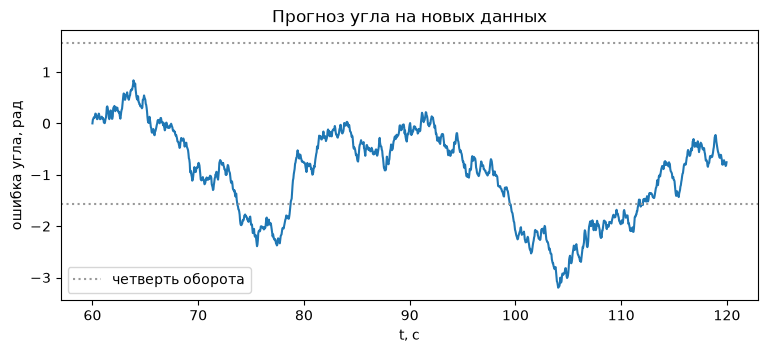

In [14]:
s = series[MAIN_ROBOT]
is_train, is_test = s['t'] < TRAIN_END, s['t'] >= TRAIN_END
equations = models[models.config == 'heading'].equations.iloc[0]
by_left = {eq['left']: eq for eq in equations}
omega_c, omega_s = -by_left['dc/dx0']['terms']['s'], by_left['ds/dx0']['terms']['c']
omega_epde = (omega_c + omega_s) / 2
omega_slope = np.polyfit(s['t'][is_train], s['phi'][is_train], 1)[0]
print(f'Скорость вращения по EPDE: {omega_epde:.2f} рад/с')
print(f'Наклон графика угла: {omega_slope:.2f} рад/с')

# Ошибка уравнения для косинуса на обучении и на новых данных.
dc = savgol_filter(s['cos_phi'], 9, 3, deriv=1, delta=1 / FPS)
for label, mask in (('обучающем участке', is_train), ('отложенном участке', is_test)):
    print(f"WAPE на {label}: {scores(dc[mask], -omega_c * s['sin_phi'][mask])['wape']:.2f}")

# Прогноз угла от конца обучающего участка при постоянной скорости.
predicted = s['phi'][is_test][0] + omega_epde * (s['t'][is_test] - TRAIN_END)
error = s['phi'][is_test] - predicted
first_miss = s['t'][is_test][np.argmax(np.abs(error) > np.pi / 2)] - TRAIN_END
print(f'Ошибка угла превышает четверть оборота через {first_miss:.0f} с')

plt.figure(figsize=(9, 3.5))
plt.plot(s['t'][is_test], error)
plt.axhline(np.pi / 2, color='0.6', ls=':', label='четверть оборота')
plt.axhline(-np.pi / 2, color='0.6', ls=':')
plt.xlabel('t, с'); plt.ylabel('ошибка угла, рад'); plt.title('Прогноз угла на новых данных'); plt.legend()
plt.show()

Скорость почти совпадает с наклоном графика, а ошибка на новых данных почти не растёт. Значит, уравнение верно описывает среднее вращение. Но угол на долгий срок оно не предсказывает: уже примерно через 14 секунд ошибка превышает четверть оборота. Скорость робота немного плавает, и эти отклонения накапливаются.

Главная проверка — сравнить данные с уравнением напрямую. Решение найденной системы при постоянной скорости: $c(t)=\cos(\phi_0+\omega t)$. Запустим его от начала новых данных.

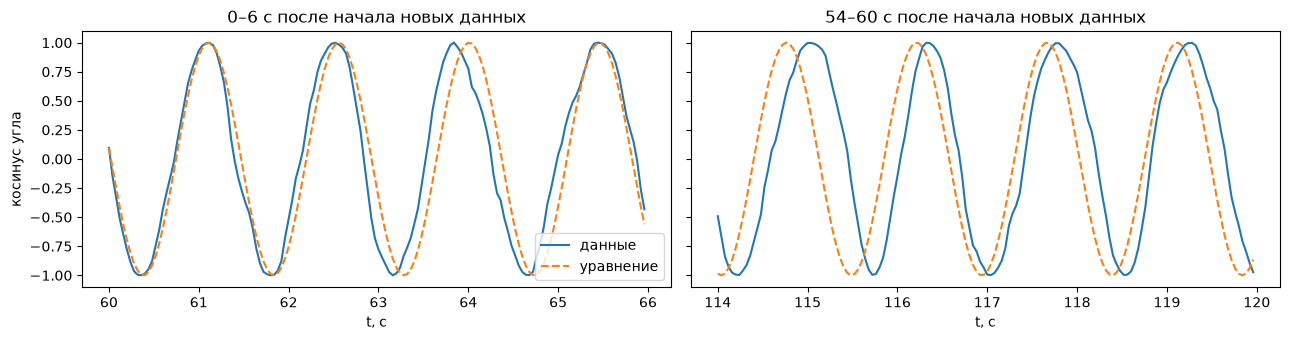

In [15]:
s = series[MAIN_ROBOT]
is_test = s['t'] >= TRAIN_END
elapsed = s['t'][is_test] - TRAIN_END
solution = np.cos(s['phi'][is_test][0] + omega_epde * elapsed)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for axis, (start, end) in zip(ax, ((0, 6), (54, 60))):
    part = (elapsed >= start) & (elapsed < end)
    axis.plot(s['t'][is_test][part], s['cos_phi'][is_test][part], label='данные')
    axis.plot(s['t'][is_test][part], solution[part], '--', label='уравнение')
    axis.set(xlabel='t, с', title=f'{start}–{end} с после начала новых данных')
ax[0].set_ylabel('косинус угла'); ax[0].legend(loc='lower right')
plt.tight_layout(); plt.show()

В первые секунды уравнение идёт вместе с данными. К концу минуты форма и период остаются теми же, но кривые заметно сдвинуты. Это тот же вывод, что и выше: среднее вращение описано верно, а фаза постепенно уходит.

### Вращение: расширенная библиотека

Разрешим вторую производную, вторую степень и произведения. В таблице оставлены только формы с фронта.

In [16]:
wide_table = show('heading_wide', only_front=True)

Показаны 17 из 250 форм.


| уравнение | сидов | фронт | невязка | нестабильность |
|---|---|---|---|---|
| $\dot{c} = - 2.36\,s + 0.126\,\ddot{s}\,s^2 - 2.24\,c^2\,s - 0.000901\,\ddot{s}\,\dot{s} - 0.0236\,\ddot{s};\quad \dot{s} = 2.22\,c - 0.108\,c^2\,\ddot{c} + 2.48\,c\,s^2 + 0.029\,\ddot{c}\,s^2 + 0.0753\,c\,s + 0.00931\,c\,\ddot{s}$ | 1 | ✓ | 0.0942 | 142 |
| $\dot{c} = - 2.36\,s + 0.126\,\ddot{s}\,s^2 - 0.0237\,\ddot{s} - 2.25\,c^2\,s - 0.000898\,\ddot{s}\,\dot{s} + 0.00546\,c;\quad \dot{s} = 2.22\,c - 0.108\,c^2\,\ddot{c} + 2.48\,c\,s^2 + 0.029\,\ddot{c}\,s^2 + 0.0753\,c\,s + 0.00931\,c\,\ddot{s}$ | 1 | ✓ | 0.0942 | 94.3 |
| $\dot{c} = - 2.35\,s + 0.126\,\ddot{s}\,s^2 - 0.0235\,\ddot{s} - 2.26\,c^2\,s - 0.0048\,c\,\ddot{s};\quad \dot{s} = 2.22\,c - 0.108\,c^2\,\ddot{c} + 2.48\,c\,s^2 + 0.029\,\ddot{c}\,s^2 + 0.0753\,c\,s + 0.00931\,c\,\ddot{s}$ | 1 | ✓ | 0.0943 | 93.1 |
| $\dot{c} = - 2.36\,s + 0.128\,\ddot{s}\,s^2 - 0.0252\,\ddot{s} - 2.25\,c^2\,s;\quad \dot{s} = 2.22\,c - 0.108\,c^2\,\ddot{c} + 2.48\,c\,s^2 + 0.029\,\ddot{c}\,s^2 + 0.0753\,c\,s + 0.00931\,c\,\ddot{s}$ | 1 | ✓ | 0.0946 | 56.6 |
| $\dot{c} = - 2.37\,s + 0.102\,\ddot{s}\,s^2 - 0.026\,c^2\,\ddot{s} - 2.26\,c^2\,s;\quad \dot{s} = 2.22\,c - 0.108\,c^2\,\ddot{c} + 2.48\,c\,s^2 + 0.029\,\ddot{c}\,s^2 + 0.0753\,c\,s + 0.00931\,c\,\ddot{s}$ | 1 | ✓ | 0.0947 | 42.9 |
| $\dot{c} = - 2.36\,s - 2.26\,c^2\,s + 0.102\,\ddot{s}\,s^2 - 0.0245\,c^2\,\ddot{s} + 0.00425\,c - 0.000913\,\ddot{s}\,\dot{s};\quad \dot{s} = 2.25\,c - 0.107\,c^2\,\ddot{c} + 2.46\,c\,s^2 + 0.0318\,\ddot{c}\,s^2$ | 1 | ✓ | 0.0954 | 27.7 |
| $\dot{c} = - 2.35\,s - 0.0246\,\ddot{s} - 2.24\,c^2\,s + 0.128\,\ddot{s}\,s^2 + 0.0186\,c\,s^2;\quad \dot{s} = 2.25\,c - 0.107\,c^2\,\ddot{c} + 2.46\,c\,s^2 + 0.0318\,\ddot{c}\,s^2$ | 1 | ✓ | 0.0957 | 21.6 |
| $\dot{c} = - 2.36\,s - 2.25\,c^2\,s + 0.128\,\ddot{s}\,s^2 - 0.0252\,\ddot{s};\quad \dot{s} = 2.25\,c - 0.107\,c^2\,\ddot{c} + 2.46\,c\,s^2 + 0.0318\,\ddot{c}\,s^2$ | 2 | ✓ | 0.0957 | 20 |
| $\dot{c} = - 2.37\,s - 0.026\,c^2\,\ddot{s} - 2.26\,c^2\,s + 0.102\,\ddot{s}\,s^2;\quad \dot{s} = 2.25\,c - 0.107\,c^2\,\ddot{c} + 2.46\,c\,s^2 + 0.0318\,\ddot{c}\,s^2$ | 2 | ✓ | 0.0958 | 6.4 |
| $\dot{c} = - 2.37\,s - 0.026\,c^2\,\ddot{s} - 2.26\,c^2\,s + 0.102\,\ddot{s}\,s^2;\quad \dot{s} = 2.35\,c + 2.37\,c\,s^2 + 0.137\,\ddot{c}\,s^2 - 0.103\,\ddot{c}$ | 2 | ✓ | 0.0989 | 5.53 |
| $\dot{c} = - 2.45\,s - 0.126\,c^2\,\ddot{s} + 0.0983\,\ddot{s} - 2.19\,c^2\,s;\quad \dot{s} = 2.25\,c - 0.107\,c^2\,\ddot{c} + 2.46\,c\,s^2 + 0.0318\,\ddot{c}\,s^2$ | 1 | ✓ | 0.1 | 5.32 |
| $\dot{c} = - 1.73\,c^2\,s + 0.0947\,\ddot{s}\,s^2 - 2.49\,s;\quad \dot{s} = 2.25\,c - 0.107\,c^2\,\ddot{c} + 2.46\,c\,s^2 + 0.0318\,\ddot{c}\,s^2$ | 2 | ✓ | 0.1 | 3.69 |
| $\dot{c} = - 1.73\,c^2\,s + 0.0947\,\ddot{s}\,s^2 - 2.49\,s;\quad \dot{s} = 2.35\,c + 2.37\,c\,s^2 + 0.137\,\ddot{c}\,s^2 - 0.103\,\ddot{c}$ | 2 | ✓ | 0.103 | 2.81 |
| $\dot{c} = - 3.31\,s + 0.0686\,\ddot{s}\,s^2;\quad \dot{s} = 2.25\,c - 0.107\,c^2\,\ddot{c} + 2.46\,c\,s^2 + 0.0318\,\ddot{c}\,s^2$ | 2 | ✓ | 0.109 | 2.3 |
| $\dot{c} = - 3.31\,s + 0.0686\,\ddot{s}\,s^2;\quad \dot{s} = 2.35\,c + 2.37\,c\,s^2 + 0.137\,\ddot{c}\,s^2 - 0.103\,\ddot{c}$ | 2 | ✓ | 0.112 | 1.43 |
| $\dot{c} = - 4.33\,s;\quad \dot{s} = 2.35\,c + 2.37\,c\,s^2 + 0.137\,\ddot{c}\,s^2 - 0.103\,\ddot{c}$ | 2 | ✓ | 0.127 | 0.631 |
| $\dot{c} = - 4.33\,s;\quad \dot{s} = 4.37\,c$ | 5 | ✓ | 0.153 | 0.00403 |

Формально широкий поиск улучшил невязку с 0,15 до 0,09, но нового закона здесь нет. Члены вида $c^2 s$ и $c\,s^2$ при $c^2+s^2=1$ переписываются через $s$ и $c$, поэтому скорость вращения размазывается между ними: коэффициент при $s$ падает с 4,3 до 2,4. Остальные члены со второй производной малы. Кроме того, каждую форму нашли один-два сида. Поэтому при сравнении сидов надо проверять, не описывают ли разные записи одно и то же, а снижение невязки само по себе не означает нового знания.

### Вращение: другая длина куска

In [17]:
rows = []
for name, length in (('heading', 1.3), ('heading_chunk26', 2.6), ('heading_chunk52', 5.2)):
    for _, row in structures(name).iterrows():
        rows.append({'длина куска, с': length, 'уравнение': '$' + row['формула'] + '$', 'сидов': row['сидов'], 'невязка': row['невязка']})
display(markdown_table(pd.DataFrame(rows)))

| длина куска, с | уравнение | сидов | невязка |
|---|---|---|---|
| 1.3 | $\dot{c} = - 4.32\,s + 0.0308\,c + 0.0231;\quad \dot{s} = 4.36\,c$ | 5 | 0.148 |
| 1.3 | $\dot{c} = - 4.31\,s + 0.0445\,c;\quad \dot{s} = 4.36\,c$ | 5 | 0.148 |
| 1.3 | $\dot{c} = - 4.3\,s;\quad \dot{s} = 4.36\,c$ | 5 | 0.148 |
| 2.6 | $\dot{c} = - 4.31\,s + 0.0497\,c + 0.0392;\quad \dot{s} = - 0.0442\,s + 4.37\,c$ | 5 | 0.13 |
| 2.6 | $\dot{c} = - 4.31\,s + 0.0497\,c + 0.0392;\quad \dot{s} = 4.37\,c$ | 5 | 0.13 |
| 2.6 | $\dot{c} = - 4.31\,s + 0.034;\quad \dot{s} = - 0.0442\,s + 4.37\,c$ | 5 | 0.13 |
| 2.6 | $\dot{c} = - 4.31\,s + 0.034;\quad \dot{s} = 4.37\,c$ | 5 | 0.13 |
| 2.6 | $\dot{c} = - 4.3\,s;\quad \dot{s} = - 0.0442\,s + 4.37\,c$ | 5 | 0.131 |
| 2.6 | $\dot{c} = - 4.3\,s;\quad \dot{s} = 4.37\,c$ | 5 | 0.131 |
| 5.2 | $\dot{c} = - 4.31\,s + 0.0519\,c;\quad \dot{s} = 4.38\,c$ | 5 | 0.136 |
| 5.2 | $\dot{c} = - 4.3\,s;\quad \dot{s} = 4.38\,c$ | 5 | 0.136 |

Форма уравнений не меняется, скорость почти та же при кусках 1,3, 2,6 и 5,2 с. Невязка немного меньше на длинных кусках, потому что EPDE может выбрать окна шире, а невязки при разных окнах нельзя сравнивать напрямую.

### Перемещение: что дают контакты

Сравним три поиска с одинаковым бюджетом. На графике одна точка соответствует одной форме уравнения, а её размер показывает, сколько сидов эту форму нашли.

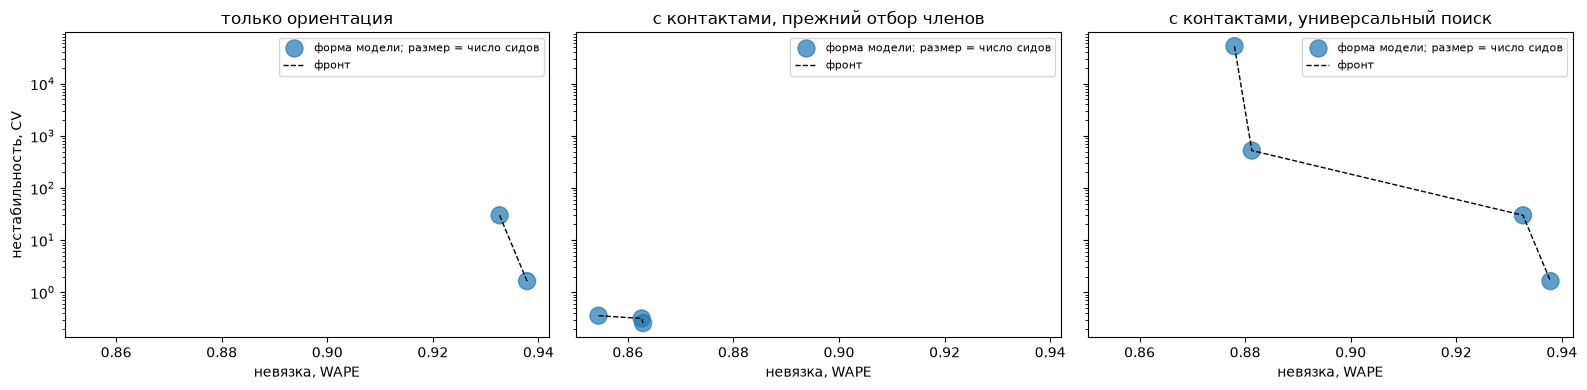

In [18]:
names = [('drift_orientation', 'только ориентация'), ('drift_repair', 'с контактами, прежний отбор членов'), ('drift', 'с контактами, универсальный поиск')]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (name, title) in zip(axes, names):
    table = structures(name)
    ax.scatter(table['невязка'], table['нестабильность'], s=25 + 25 * table['сидов'], alpha=.7, label='форма модели; размер = число сидов')
    front = table[table['на_фронте']].sort_values('невязка')
    ax.plot(front['невязка'], front['нестабильность'], 'k--', lw=1, label='фронт')
    ax.set(xlabel='невязка, WAPE', title=title); ax.set_yscale('log'); ax.legend(fontsize=8)
axes[0].set_ylabel('нестабильность, CV')
plt.tight_layout(); plt.show()

In [19]:
def pick(name, equation, label):
    row = structures(name).set_index('форма').loc[structure_of([equation])]
    return {'что сравниваем': label, 'уравнение': '$' + row['формула'] + '$', 'сидов': row['сидов'],
            'WAPE на обучении': row['WAPE_обучение'], 'WAPE на новых данных': row['WAPE_отложенный']}


only_orientation_eq = main_form('drift_orientation', 'du/dx0', required=['sin_phi'], allowed=['sin_phi', 'cos_phi'])
with_push_eq = main_form('drift', 'du/dx0', required=['sin_phi', 'push_x'], allowed=['sin_phi', 'cos_phi', 'push_x'])
full = structures('drift')
comparison = pd.DataFrame([
    {'что сравниваем': 'скорость равна нулю', 'уравнение': '—', 'сидов': '—', 'WAPE на обучении': 1.0, 'WAPE на новых данных': 1.0},
    pick('drift_orientation', only_orientation_eq, 'только ориентация'),
    pick('drift', with_push_eq, 'ориентация и толчок'),
    pick('drift', models[(models.config == 'drift') & (models.structure == full['форма'].iloc[0])].equations.iloc[0][0],
         'самая точная на обучении'),
])
display(markdown_table(comparison))
repair = structures('drift_repair')
print('Форм с толчком: универсальный поиск', full['модель'].str.contains('push_x').sum(), 'из', len(full),
      '; прежний отбор', repair['модель'].str.contains('push_x').sum(), 'из', len(repair))

| что сравниваем | уравнение | сидов | WAPE на обучении | WAPE на новых данных |
|---|---|---|---|---|
| скорость равна нулю | — | — | 1 | 1 |
| только ориентация | $\dot{X} = 1.24\,\sin\phi - 0.0819$ | 5 | 0.843 | 0.893 |
| ориентация и толчок | $\dot{X} = 1.12\,\sin\phi + 0.621\,p_x - 0.135$ | 5 | 0.788 | 0.878 |
| самая точная на обучении | $\dot{X} = 1.12\,\sin\phi + 0.621\,p_x - 0.135$ | 5 | 0.788 | 0.878 |

Форм с толчком: универсальный поиск 2 из 4 ; прежний отбор 3 из 3


Сравним данные с уравнениями напрямую: скорость робота и координату, которую получим, если сложить скорость из уравнения шаг за шагом.

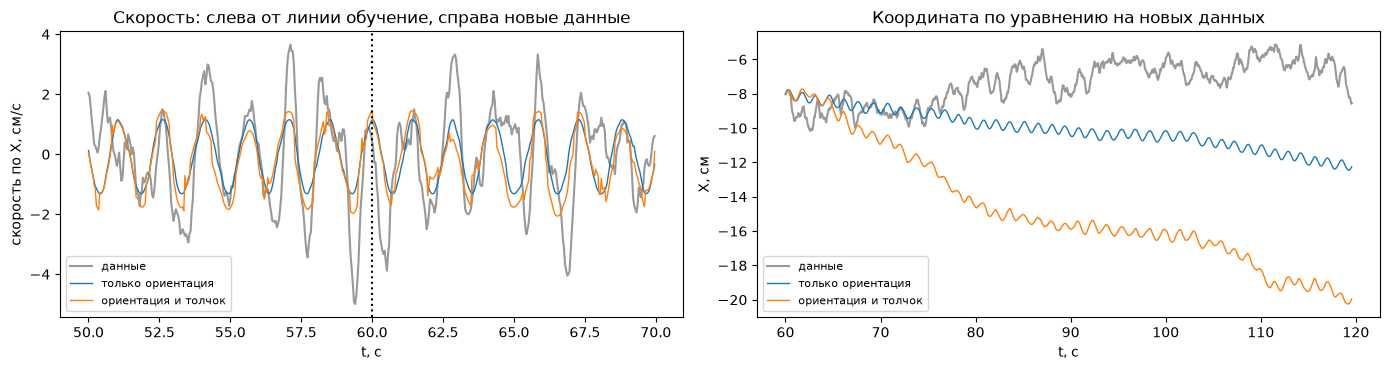

In [20]:
s = series[MAIN_ROBOT]
velocity = forward_velocity(s['X'], s['t'], 10)
n = len(velocity)
time_axis = s['t'][:n]
columns = {name: s[name][:n] for name in ('cos_phi', 'sin_phi', 'push_x')}
columns['t'] = time_axis
only_orientation = predict_derivative(only_orientation_eq, columns)
with_push = predict_derivative(with_push_eq, columns)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
part = (time_axis >= 50) & (time_axis < 70)
ax[0].plot(time_axis[part], velocity[part], color='0.6', label='данные')
ax[0].plot(time_axis[part], only_orientation[part], label='только ориентация', lw=1)
ax[0].plot(time_axis[part], with_push[part], label='ориентация и толчок', lw=1)
ax[0].axvline(TRAIN_END, color='k', ls=':')
ax[0].set(xlabel='t, с', ylabel='скорость по X, см/с', title='Скорость: слева от линии обучение, справа новые данные'); ax[0].legend(fontsize=8)

new = time_axis >= TRAIN_END
step = 1 / FPS
ax[1].plot(time_axis[new], s['X'][:n][new], color='0.6', label='данные')
for label, rate in (('только ориентация', only_orientation), ('ориентация и толчок', with_push)):
    ax[1].plot(time_axis[new], s['X'][:n][new][0] + np.cumsum(rate[new]) * step, label=label, lw=1)
ax[1].set(xlabel='t, с', ylabel='X, см', title='Координата по уравнению на новых данных'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Скорость.** Оба уравнения повторяют ритм колебаний, но не достают до больших пиков данных. Значительная часть движения остаётся необъяснённой, это видно и по ошибке 0,88–0,89.

**Координата.** Оба уравнения постепенно уходят от данных, а уравнение с толчком — сильнее, примерно на 12 см за минуту. Большую часть этого ухода даёт небольшой свободный член: $-0{,}08$ и $-0{,}14$ см/с за минуту дают смещение около 5 и 8 см. Небольшие систематические ошибки скорости накапливаются, поэтому хорошая ошибка на одном шаге ещё не означает хороший прогноз на минуту. Такой график легко показывает то, чего не видно в таблице.

Из этого сравнения следуют три вывода.

1. **Толчок соседей помогает.** Универсальный поиск во всех пяти сидах нашёл форму с ориентацией и толчком. Коэффициент толчка положителен, то есть сосед отталкивает робота, а ошибка на новых данных снижается с 0,89 до 0,88. Выигрыш небольшой: большая часть движения остаётся необъяснённой.
2. **Способ отбора членов меняет ответ.** Прежний отбор тоже включает толчок, но с коэффициентом 0,12–0,31 вместо 0,6 и чаще добавляет $\cos\phi$. Его формы немного точнее на новых данных (0,86–0,87). Если бы мы проверили только один способ, то не увидели бы, что величина эффекта зависит от настроек.
3. **Признак стены у этого робота не находится.** Робот 72 почти не подходит к стене на обучающем участке, поэтому и оценить её по нему нельзя.

Ниже все найденные формы универсального поиска.

In [21]:
drift_table = show('drift')

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{X} = 1.12\,\sin\phi + 0.621\,p_x - 0.135$ | 5 | ✓ | 0.878 | 5.25e+04 | 0.878 |
| $\dot{X} = 1.12\,\sin\phi + 0.04\,X + 0.599\,p_x$ | 5 | ✓ | 0.881 | 523 | 0.911 |
| $\dot{X} = 1.24\,\sin\phi - 0.0819$ | 5 | ✓ | 0.933 | 29.9 | 0.893 |
| $\dot{X} = 1.27\,\sin\phi$ | 5 | ✓ | 0.938 | 1.63 | 0.893 |

Самая точная на обучении форма здесь оказалась и самой точной на новых данных. Новые данные использованы только для проверки, а не для выбора уравнения. Если бы мы выбирали по ним, для честной оценки понадобился бы ещё один независимый участок.

### Перемещение: робот у стены

In [22]:
wall_table = show('drift_wall_robot')

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{X} = - 0.767\,\sin\phi + 0.602\,\cos\phi$ | 5 | ✓ | 0.88 | 637 | 0.977 |
| $\dot{X} = - 0.788\,\sin\phi$ | 5 | ✓ | 0.94 | 270 | 0.906 |
| $\dot{X} = - 0.843\,\sin\phi - 0.164$ | 5 | ✓ | 0.96 | 51.4 | 0.924 |

У робота 38 поиск толчка не нашёл, а признак стены тоже не вошёл ни в одну форму. Ориентация входит с другим знаком, чем у робота 72: у каждого робота своё направление собственного движения относительно метки. Лучшая на новых данных форма с одной ориентацией даёт ошибку 0,91.

### Перемещение: все 30 роботов

Два робота мало что доказывают. Запускать EPDE на всех долго, поэтому проверим толчок обычной линейной регрессией на тех же признаках. Здесь показатель $R^2$: чем больше, тем лучше, а значение 0 соответствует предсказанию средним.

In [23]:
# Обычная регрессия, а не EPDE: проверяем, на всех ли роботах контакт помогает на новых данных.
keep = t < TEST_END
contacts_all = contact_features(x[keep], y[keep], spin_rates(t[keep], phi[keep]), xc, yc, radius)
lag = 10
n = keep.sum() - lag
fit_mask, test_mask = t[:n] < TRAIN_END, t[:n] >= TRAIN_END
results = {'ориентация': [], 'ориентация и толчок': [], 'ориентация, толчок и стена': []}
for j in range(len(ids)):
    velocity = forward_velocity(x[keep, j] / scale_px, t[keep], lag)
    base = [np.cos(phi[:n, j]), np.sin(phi[:n, j])]
    for label, columns in (('ориентация', base), ('ориентация и толчок', base + [contacts_all['push_x'][:n, j]]),
                           ('ориентация, толчок и стена', base + [contacts_all['push_x'][:n, j], contacts_all['wall_x'][:n, j]])):
        A = np.column_stack(columns + [np.ones(n)])
        coefficients = np.linalg.lstsq(A[fit_mask], velocity[fit_mask], rcond=None)[0]
        results[label].append(scores(velocity[test_mask], A[test_mask] @ coefficients)['r2'])
summary = pd.DataFrame(results)
display(pd.DataFrame({'медиана R2 на отложенном участке': summary.median(), 'лучше, чем только ориентация, роботов из 30': (summary.sub(summary['ориентация'], axis=0) > 0).sum()}).round(3))

,медиана R2 на отложенном участке,"лучше, чем только ориентация, роботов из 30"
ориентация,0.428,0
ориентация и толчок,0.501,28
"ориентация, толчок и стена",0.516,26


Толчок улучшает результат на новых данных у 28 роботов из 30, поэтому результат для робота 72 не случайность. Это проверка признака, а не результат EPDE.

### Перемещение: другой шаг приращения

Скорость мы считаем по изменению координаты за лаг. Посмотрим, как коэффициенты зависят от него. Для простоты снова берём линейную регрессию.

In [24]:
rows = []
s = series[MAIN_ROBOT]
for lag in (5, 10, 20):
    velocity = forward_velocity(s['X'], s['t'], lag)
    n = len(velocity)
    mask = s['t'][:n] < TRAIN_END
    A = np.column_stack([s['cos_phi'][:n], s['sin_phi'][:n], s['push_x'][:n], np.ones(n)])
    cos_part, sin_part, push_part, _ = np.linalg.lstsq(A[mask], velocity[mask], rcond=None)[0]
    rows.append({'лаг, с': lag / FPS, 'поворот за лаг, рад': omega_epde * lag / FPS,
                 'при cos(phi)': cos_part, 'при sin(phi)': sin_part, 'при толчке': push_part})
display(pd.DataFrame(rows).style.hide(axis='index').format(precision=2))

"лаг, с","поворот за лаг, рад",при cos(phi),при sin(phi),при толчке
0.20,0.87,-0.92,1.09,0.73
0.40,1.73,-0.33,1.12,0.75
0.80,3.47,0.40,0.46,0.61


Коэффициенты при ориентации сильно меняются с лагом, потому что за время приращения робот успевает заметно повернуться: при лаге 0,8 с примерно на пол-оборота. Поэтому то, что при лаге 0,4 с главным оказался $\sin\phi$, говорит скорее о выбранном лаге, чем о самом роботе. Коэффициент при толчке меняется мало, и ему можно доверять больше. Поиски EPDE с другими лагами ведут себя так же: при лаге 0,2 с толчок не находится, при лаге 0,8 с находится с коэффициентом около 0,36 (их итог в сводке ниже).

### Перемещение: вторая производная

До сих пор в уравнениях были только первые производные. Разрешим и вторую: изменение скорости, что-то вроде ускорения робота. Для второй производной окно нужно шире, поэтому куски здесь по 2,6 с.

In [25]:
second_table = show('drift_second')

| уравнение | сидов | фронт | невязка | нестабильность |
|---|---|---|---|---|
| $\ddot{X} = 1.6\,p_x + 5.59\,\cos\phi - 0.0451\,\dot{X}$ | 5 | ✓ | 0.8 | 294 |
| $\ddot{X} = - 0.15\,X + 5.82\,\cos\phi$ | 5 | ✓ | 0.819 | 181 |
| $\ddot{X} = 0.691\,\sin\phi + 5.89\,\cos\phi + 0.388$ | 5 | ✓ | 0.823 | 64.4 |
| $\ddot{X} = - 0.155\,X + 6.32\,\cos\phi + 0.194\,\dot{X}$ | 5 | ✓ | 0.826 | 55 |
| $\ddot{X} = 5.82\,\cos\phi$ | 5 | ✓ | 0.83 | 7.84 |

Все сиды нашли простую форму $\ddot X=5{,}8\cos\phi$ и её варианты с толчком и координатой. Это не новый закон, а следствие уже найденного: если продифференцировать $\dot X=1{,}24\sin\phi$ при вращении с постоянной скоростью, получится $\ddot X=1{,}24\,\omega\cos\phi$, то есть около $5{,}4\cos\phi$. Проверим это и заодно посмотрим, чем вторая производная опасна в прямой оценке по точкам.

In [26]:
lag, h = 10, 0.4
rng = np.random.default_rng(0)
random_walk = np.cumsum(rng.normal(size=1500)) * 0.1
rows = []
for label, series_x, time_x in (('робот 72', series[MAIN_ROBOT]['X'][is_train], series[MAIN_ROBOT]['t'][is_train]),
                                ('случайное блуждание', random_walk, np.arange(1500) / FPS)):
    velocity = forward_velocity(series_x, time_x, lag)
    current, following = velocity[:-lag], velocity[lag:]
    second = (following - current) / h
    k = (second * current).sum() / (current ** 2).sum()
    rows.append({'данные': label, 'коэффициент k в x\'\' = k·x\'': k, 'WAPE такого уравнения': np.abs(second - k * current).sum() / np.abs(second).sum()})
display(pd.DataFrame(rows).style.hide(axis='index').format(precision=2))
print('Для сравнения, -1 / 0,4 с =', -1 / h)

# Слабая постановка: уравнение для второй производной и согласие с уравнением для скорости.
second_eq = main_form('drift_second', 'd^2u/dx0^2', required=['cos_phi'])
first_eq = main_form('drift_orientation', 'du/dx0', required=['sin_phi'], allowed=['sin_phi', 'cos_phi'])
print('Уравнение для второй производной:', pretty([second_eq]))
print('Уравнение для скорости:', pretty([first_eq]))
print(f"Если продифференцировать скорость, коэффициент при cos(phi) будет {first_eq['terms']['sin_phi'] * omega_epde:.2f} "
      f"(коэффициент при sin(phi), умноженный на скорость вращения {omega_epde:.2f} рад/с)")

данные,коэффициент k в x'' = k·x',WAPE такого уравнения
робот 72,-2.48,0.70
случайное блуждание,-2.49,0.71


Для сравнения, -1 / 0,4 с = -2.5
Уравнение для второй производной: d^2u/dx0^2 = +1.6·push_x +5.59·cos_phi -0.0451·du/dx0
Уравнение для скорости: du/dx0 = +1.24·sin_phi -0.0819
Если продифференцировать скорость, коэффициент при cos(phi) будет 5.35 (коэффициент при sin(phi), умноженный на скорость вращения 4.33 рад/с)


Коэффициент 5,8 близок к расчётному 5,4: уравнение для второй производной согласуется с уравнением для скорости.

Регрессия в таблице показывает ловушку прямой оценки по точкам. Если вторую производную считать как разность следующей и текущей скорости, делённую на лаг, то связь $\ddot x=k\,\dot x$ с $k\approx-1/0{,}4$ находится даже на случайном блуждании, причём с той же ошибкой, что и у робота. Текущая скорость оказывается в обеих частях уравнения. В слабой постановке производные переносятся на гладкую функцию окна, и связи с коэффициентом около $-2{,}5$ EPDE не нашёл.

Итог: прежде чем считать новый член законом, полезно проверить его на данных, где закона заведомо нет, и сравнить с тем, что следует из уже найденных уравнений.

Смешанные производные здесь недоступны: у одного робота есть только ось времени, а для них нужны хотя бы две оси, например время и пространство.

### Перемещение в полярной координате

Повторим поиск для расстояния до центра $r$. Признаки те же, но взяты вдоль радиуса.

In [27]:
radial_table = show('radial')
s = series[MAIN_ROBOT]
display(pd.DataFrame([{'участок': label, 'среднее расстояние до центра, см': s['r'][mask].mean(), 'доля кадров у стены': (s['wall_r'][mask] != 0).mean()}
                      for label, mask in (('обучающий', s['t'] < TRAIN_END), ('отложенный', s['t'] >= TRAIN_END))]).style.hide(axis='index').format(precision=2))

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{r} = 0.738\,p_r - 0.191\,\cos(\phi-\alpha) + 1.14\,\sin(\phi-\alpha) + 0.423$ | 5 | ✓ | 0.816 | 2.14e+03 | 1.21 |
| $\dot{r} = 1.27\,\sin(\phi-\alpha) + 0.134$ | 5 | ✓ | 0.842 | 70.2 | 1.05 |
| $\dot{r} = 1.38\,\sin(\phi-\alpha)$ | 5 | ✓ | 0.858 | 9.14 | 1.08 |

участок,"среднее расстояние до центра, см",доля кадров у стены
обучающий,12.41,0.07
отложенный,16.55,0.64


На обучении результат похож на поиск по $X$: ориентация и толчок, и толчок снова отталкивает. Но на новых данных все уравнения хуже предсказания нулевой скорости: ошибка больше 1.

Вторая таблица объясняет почему: робот переходит к стене. На обучении он у стены 7% времени, на проверке 64%. Вероятно, у стены он уже не может свободно двигаться вдоль радиуса, и уравнение, найденное при другом поведении, перестаёт работать. Поэтому полезно смотреть не только на значение ошибки, но и на то, чем новые данные отличаются от обучающих.

### Как можно менять результат: сводка

Соберём в одну таблицу всё, что мы меняли в поиске по $X$, и добавим ещё несколько вариантов. Это примеры того, что можно пробовать на своих данных: другие токены и другие настройки метода.

В столбце лучшей невязки приведена форма, лучшая на обучении, а рядом её ошибка на новых данных. Последний столбец показывает наименьшую ошибку на новых данных среди всех найденных форм; выбирать уравнение по нему нельзя, он нужен только для понимания.

In [28]:
variants = [
    ('Токены', 'только ориентация', 'drift_orientation'),
    ('Токены', 'ориентация, толчок и стена', 'drift'),
    ('Токены', 'то же и память скорости', 'drift_memory'),
    ('Токены', 'то же и произведения токенов', 'drift_products'),
    ('Токены', 'функции времени вместо ориентации', 'drift_trig'),
    ('Метод', 'прежний отбор членов', 'drift_repair'),
    ('Метод', 'другая мера нестабильности', 'drift_chi2'),
    ('Производная', 'лаг 0,2 с', 'drift_lag5'),
    ('Производная', 'лаг 0,8 с', 'drift_lag20'),
    ('Производная', 'без усреднения за лаг', 'drift_raw'),
    ('Производная', 'вторая производная', 'drift_second'),
]
rows = []
for group, label, name in variants:
    table = structures(name)
    best = table.iloc[0]
    rows.append({'что меняем': group, 'вариант': label, 'форм': len(table), 'лучшая невязка': best['невязка'],
                 'её ошибка на новых данных': best.get('WAPE_отложенный', np.nan),
                 'лучшая ошибка на новых данных': table['WAPE_отложенный'].min() if 'WAPE_отложенный' in table else np.nan,
                 'есть контакты': table['модель'].str.contains('push_x|wall_x').any()})
display(pd.DataFrame(rows).style.hide(axis='index').format(precision=2, na_rep='—'))

что меняем,вариант,форм,лучшая невязка,её ошибка на новых данных,лучшая ошибка на новых данных,есть контакты
Токены,только ориентация,2,0.93,0.89,0.89,False
Токены,"ориентация, толчок и стена",4,0.88,0.88,0.88,True
Токены,то же и память скорости,4,0.88,0.88,0.88,True
Токены,то же и произведения токенов,9,0.85,0.95,0.87,True
Токены,функции времени вместо ориентации,45,0.86,1.08,0.96,True
Метод,прежний отбор членов,3,0.85,0.87,0.86,True
Метод,другая мера нестабильности,5,0.88,0.88,0.88,True
Производная,"лаг 0,2 с",3,0.98,0.91,0.91,False
Производная,"лаг 0,8 с",4,0.84,0.94,0.94,True
Производная,без усреднения за лаг,4,0.94,1.08,1.08,False


**Что можно вынести из таблицы.**

- **Больше токенов снижают невязку на обучении, но не всегда помогают на новых данных.** Невязка падает с 0,93 до 0,85, а лучшая ошибка на новых данных остаётся около 0,86–0,89. Память скорости не вошла ни в одну форму, а произведения токенов на новых данных хуже: 0,95 у самой точной на обучении формы.
- **Токен должен отражать механизм.** Функции времени вместо измеренной ориентации на новых данных почти не лучше нулевой скорости (лучшая ошибка 0,96, а у самой точной на обучении формы 1,08): фаза робота плавает, и чистая синусоида от времени её теряет.
- **Настройки отбора меняют ответ.** Прежний отбор членов даёт другие коэффициенты толчка, а другая мера нестабильности меняет порядок форм на фронте. Поэтому полезно пробовать больше одного варианта.
- **Подготовка данных важнее тонкой настройки.** Без усреднения за лаг слабая постановка ищет другую величину, и на новых данных все её формы хуже нулевой скорости (1,08). Сравнивать невязку между строками с разной подготовкой нельзя; смотрите на ошибку на новых данных и на форму.

Общий порядок действий: начните с простого уравнения, меняйте по одному параметру, сравнивайте при одном бюджете и проверяйте на новых данных.

## 5. Мезоуровень: поля роя

До сих пор мы смотрели на отдельных роботов. Теперь опишем рой целиком: разобьём арену на сетку и в каждой клетке посчитаем, сколько там роботов и куда они в среднем повёрнуты. Так получаются поля, и для них можно искать уравнения в частных производных: с производными по времени и по двум координатам. Это промежуточный масштаб между отдельными роботами и всей ареной, поэтому его называют мезоуровнем.

- **Плотность $\rho$:** какая доля площади вокруг точки занята роботами.
- **Поляризация $P=(P_x,P_y)$:** средний вектор ориентации роботов вокруг точки.
- **$W=(W_x,W_y)$:** тот же вектор, но каждый робот взят со своей скоростью вращения.

Каждый робот размазывается по соседним клеткам гауссианой шириной в диаметр робота. Сетка 14 × 14 занимает квадрат, вписанный в арену, шаг по времени 0,08 с. Центр арены и скорости вращения оцениваем только по обучающему участку. Окна слабой постановки здесь трёхмерные: по времени и по двум координатам.

Для частиц, которые сами движутся и вращаются, ожидают такие уравнения:

$$
\rho_t=-v\,\nabla\!\cdot P+D\,\Delta\rho,\qquad P_{x,t}=-W_y-D_r P_x+\dots
$$

Первое говорит, что плотность переносится туда, куда повёрнуты роботы, и расплывается. Второе — что поляризация поворачивается вместе с роботами и постепенно теряет согласованность.

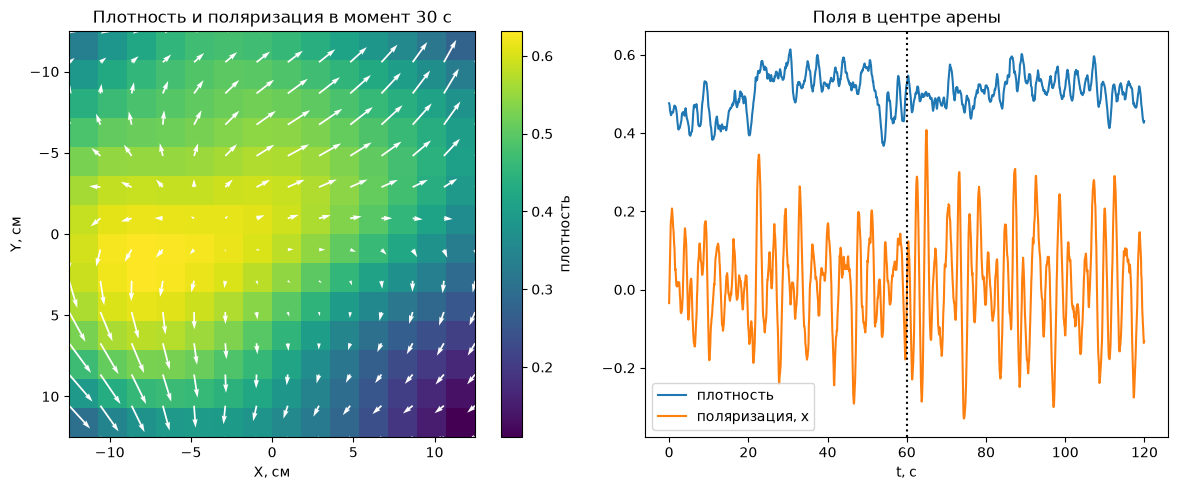

Размер полей на обучающем участке (время, x, y): (750, 14, 14)


In [29]:
moment = np.argmin(np.abs(fields['t'] - 30))
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
image = ax[0].imshow(fields['rho'][moment].T, origin='lower', extent=[fields['g'][0], fields['g'][-1]] * 2, cmap='viridis')
fig.colorbar(image, ax=ax[0], label='плотность')
ax[0].quiver(fields['g'], fields['g'], fields['Px'][moment].T, fields['Py'][moment].T, color='white')
ax[0].set(xlabel='X, см', ylabel='Y, см', title='Плотность и поляризация в момент 30 с')
ax[0].invert_yaxis()
ax[1].plot(fields['t'], fields['rho'][:, 7, 7], label='плотность')
ax[1].plot(fields['t'], fields['Px'][:, 7, 7], label='поляризация, x')
ax[1].axvline(TRAIN_END, color='k', ls=':')
ax[1].set(xlabel='t, с', title='Поля в центре арены'); ax[1].legend()
plt.tight_layout(); plt.show()
print('Размер полей на обучающем участке (время, x, y):', fields['rho'][fields['t'] < TRAIN_END].shape)

### Поиск без ограничений

Сначала дадим EPDE три поля и разрешим производные до второго порядка по координатам. Левую часть уравнения алгоритм выбирает сам.

In [30]:
free_table = show('field_free', top=5)

Показаны 5 из 245 форм.


| уравнение | сидов | фронт | невязка | нестабильность |
|---|---|---|---|---|
| $\partial_{yy} P_x = - 0.0225\,P_x;\quad \partial_{xx} P_y = - 0.00227\,\rho - 0.0212\,P_y + 0.000912;\quad \partial_{xx} \rho = - 0.0117\,\rho + 0.172\,\partial_{yy} \rho + 0.00455$ | 1 | ✓ | 0.752 | 495 |
| $\partial_{yy} P_x = - 0.00509\,\partial_{x} P_x - 0.0247\,P_x + 0.00743\,\partial_{x} \rho;\quad \partial_{xx} P_y = - 0.0202\,P_y - 0.0129\,\partial_{yy} P_y;\quad \partial_{xx} \rho = - 0.0143\,\rho + 0.00557$ | 1 | ✓ | 0.753 | 489 |
| $\partial_{yy} P_x = - 0.0227\,P_x - 0.00379\,\partial_{x} P_x;\quad \partial_{xx} P_y = - 0.00227\,\rho - 0.0212\,P_y + 0.000912;\quad \partial_{xx} \rho = - 0.0143\,\rho + 0.00557$ | 1 |  | 0.753 | 509 |
| $\partial_{yy} P_x = - 0.0225\,P_x;\quad \partial_{yy} P_y = - 0.0212\,P_y;\quad \partial_{xx} \rho = - 0.0117\,\rho + 0.172\,\partial_{yy} \rho + 0.00455$ | 1 | ✓ | 0.753 | 74.3 |
| $\partial_{yy} P_x = - 0.0227\,P_x - 0.00379\,\partial_{x} P_x;\quad \partial_{yy} P_y = - 0.0212\,P_y;\quad \partial_{xx} \rho = - 0.0117\,\rho + 0.172\,\partial_{yy} \rho + 0.00455$ | 1 | ✓ | 0.753 | 69.8 |

Почти каждую систему нашёл только один сид. В левой части стоят производные по координатам, например $\partial_{yy} P_x$, выраженные через другие величины. Такие записи ничего не говорят о том, как поля меняются во времени, и между сидами не повторяются. Поэтому дальше левую часть уравнения нужно закрепить.

### Производная по времени в левой части

EPDE ставит в левую часть только член, где есть производная самой переменной. Поэтому оставим полю только производную по времени, а производные по координатам подадим как свои токены, так же, как раньше толчок и стену. Тогда слева неизбежно окажется скорость изменения поля.

Ищем по отдельному уравнению для плотности и для каждой компоненты поляризации. Токены выбраны из ожидаемой формы с запасом: в каждой библиотеке есть и лишние кандидаты.

In [31]:
rho_table = show('field_rho')

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{\rho} = 0.492\,\partial_x\rho - 0.679\,\nabla\cdot P + 0.00217$ | 5 | ✓ | 0.956 | 588 | 0.948 |
| $\dot{\rho} = 0.418\,\partial_x\rho - 0.736\,\nabla\cdot P$ | 5 | ✓ | 0.958 | 40.3 | 0.946 |
| $\dot{\rho} = - 0.666\,\nabla\cdot P$ | 5 | ✓ | 0.962 | 3.67 | 0.948 |
| $\dot{\rho} = - 0.00177\,\rho$ | 5 | ✓ | 1 | 2.77 | 1 |

То же уравнение плотности при шаге 0,4 с вместо 0,08 с:

In [32]:
rho_slow_table = show('field_rho_lag5')

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{\rho} = 0.0948\,\rho - 0.754\,\nabla\cdot P - 0.0432$ | 5 | ✓ | 0.936 | 807 | 0.956 |
| $\dot{\rho} = - 0.811\,\nabla\cdot P + 0.301\,\Delta\rho + 0.0227\,\rho$ | 5 | ✓ | 0.947 | 88.7 | 0.942 |
| $\dot{\rho} = 0.00867\,\rho - 0.871\,\nabla\cdot P$ | 5 | ✓ | 0.947 | 13.2 | 0.928 |
| $\dot{\rho} = 0.00402\,\rho$ | 5 | ✓ | 0.992 | 3.69 | 1 |

In [33]:
px_table = show('field_Px')

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{P_x} = - 0.963\,W_y - 0.282\,\partial_x P_x$ | 5 | ✓ | 0.262 | 35.7 | 0.389 |
| $\dot{P_x} = - 0.975\,W_y$ | 5 | ✓ | 0.263 | 0.0111 | 0.389 |

In [34]:
py_table = show('field_Py')

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{P_y} = 0.947\,W_x - 0.0117\,\rho + 1.2\,\Delta P_y$ | 4 | ✓ | 0.263 | 583 | 0.391 |
| $\dot{P_y} = 0.957\,W_x - 0.0156\,\rho$ | 5 | ✓ | 0.264 | 2.08 | 0.394 |
| $\dot{P_y} = 0.959\,W_x$ | 5 | ✓ | 0.266 | 0.0101 | 0.395 |

**Поляризация.** Все пять сидов нашли одно и то же:

$$
P_{x,t}=-0{,}98\,W_y,\qquad P_{y,t}=+0{,}96\,W_x .
$$

Два уравнения зеркальны, как и должно быть. Коэффициент около 1 при $W$ прямо следует из того, что каждый робот вращается: значит, поиск нашёл верный механизм. На новых данных $R^2\approx0{,}84$, ошибка 0,39. Затухание согласованности $-D_r P$ в этой постановке не выделилось: на окнах в доли секунды оно слабее поворота.

**Плотность.** Все пять сидов нашли перенос $\rho_t=-0{,}67\,\nabla\!\cdot P$: плотность убывает там, откуда роботы повёрнуты наружу. Но объясняет он мало: $R^2\approx0{,}10$ на новых данных. При шаге 0,4 с перенос сильнее, $-0{,}87\,\nabla\!\cdot P$, и результат немного лучше, $R^2\approx0{,}12$; в одной из форм появляется и расплывание (лапласиан). Это тот же урок, что и с лагом у отдельного робота: медленные эффекты видны только на достаточно длинном шаге.

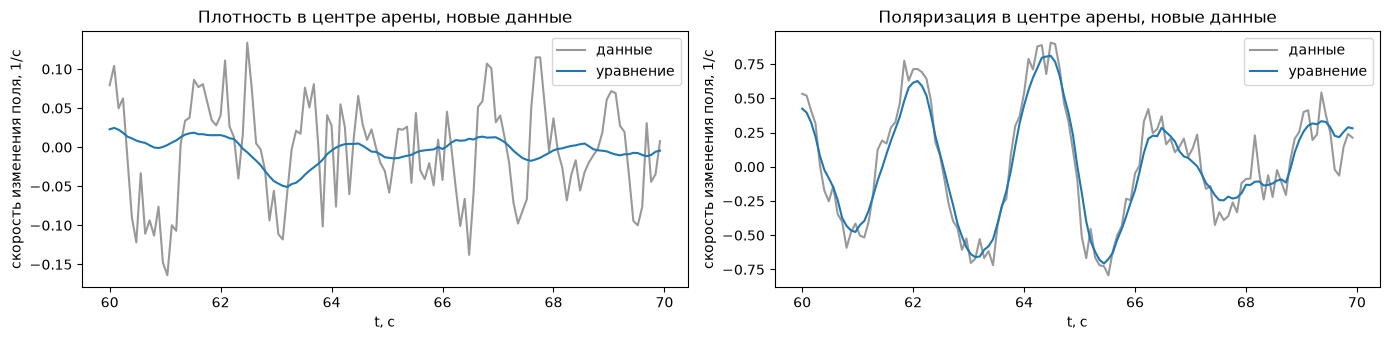

In [35]:
lag = 1
rate = {var: (fields[var][lag:] - fields[var][:-lag]) / (fields['t'][lag] - fields['t'][0]) for var in ('rho', 'Px')}
n = len(rate['rho'])
time_axis = fields['t'][:n]
part = (time_axis >= TRAIN_END) & (time_axis < TRAIN_END + 10)
best = {var: main_form(f'field_{var}', f'd{var}/dx0') for var in ('rho', 'Px')}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for axis, var, title in ((ax[0], 'rho', 'Плотность в центре арены'), (ax[1], 'Px', 'Поляризация в центре арены')):
    eq = best[var]
    prediction = eq['intercept'] + sum(k * fields[name][:n] for name, k in eq['terms'].items())
    axis.plot(time_axis[part], rate[var][part, 7, 7], color='0.6', label='данные')
    axis.plot(time_axis[part], prediction[part, 7, 7], label='уравнение')
    axis.set(xlabel='t, с', ylabel='скорость изменения поля, 1/с', title=title + ', новые данные'); axis.legend()
plt.tight_layout(); plt.show()

Для поляризации уравнение почти совпадает с данными и на новой минуте. Для плотности уравнение повторяет только общий ход, а быстрые колебания остаются необъяснёнными.

Итог по полям: если закрепить в левой части производную по времени и подать производные по координатам как токены, EPDE находит ожидаемые уравнения, причём одинаково во всех сидах. Без этого результат не повторяется.

### Поля в полярных координатах

Квадрат внутри арены не доходит до стены. Чтобы посмотреть на всю арену, построим те же поля на полярной сетке: 12 колец от 2 см до края области, куда доходят центры роботов, и 24 угла по кругу. Поляризацию разложим на радиальную часть $P_r$ (от центра к стене) и угловую $P_\theta$ (вдоль стены).

В полярных координатах у операторов появляются множители с радиусом, поэтому токены приходится пересчитать:

$$
\nabla\cdot P=\partial_r P_r+\frac{P_r}{r}+\frac{1}{r}\,\partial_\theta P_\theta,\qquad
\Delta\rho=\partial_{rr}\rho+\frac{1}{r}\,\partial_r\rho+\frac{1}{r^2}\,\partial_{\theta\theta}\rho .
$$

По углу сетка замкнута, поэтому производные по нему берутся по кругу. Для поляризации ожидаем то же, что и в декартовых координатах: $P_{r,t}=-W_\theta-D_r P_r$.

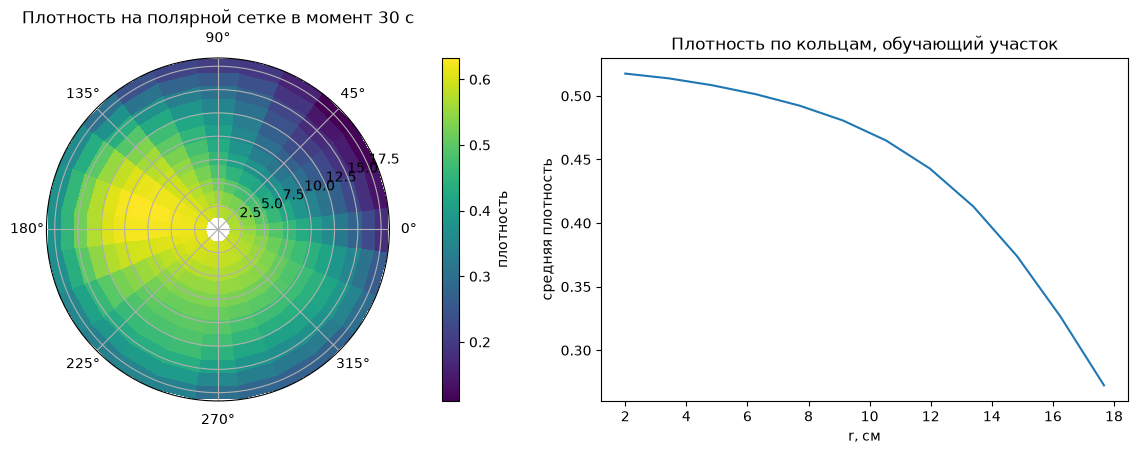

In [36]:
rings, angles = polar_fields['axes']
moment = np.argmin(np.abs(polar_fields['t'] - 30))
fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection='polar')
mesh = ax.pcolormesh(np.append(angles, np.pi), rings, np.c_[polar_fields['rho'][moment], polar_fields['rho'][moment][:, :1]], shading='auto')
fig.colorbar(mesh, ax=ax, label='плотность', pad=0.1)
ax.set_title('Плотность на полярной сетке в момент 30 с')
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(rings, polar_fields['rho'][polar_fields['t'] < TRAIN_END].mean(axis=(0, 2)))
ax2.set(xlabel='r, см', ylabel='средняя плотность', title='Плотность по кольцам, обучающий участок')
plt.tight_layout(); plt.show()

In [37]:
polar_rho_table = show('polar_rho')

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{\rho} = - 1.02\,\nabla\cdot P + 0.0181\,\rho + 2.01\,\Delta\rho$ | 5 | ✓ | 0.892 | 8.82e+03 | 0.917 |
| $\dot{\rho} = - 1.28\,\nabla\cdot P + 2.6\,\Delta\rho + 0.0118$ | 5 | ✓ | 0.896 | 882 | 0.917 |
| $\dot{\rho} = - 1.18\,\nabla\cdot P - 0.06\,P_r$ | 5 | ✓ | 0.909 | 29.3 | 0.944 |
| $\dot{\rho} = 0.0241\,\rho + 3.95\,\Delta\rho$ | 5 | ✓ | 0.99 | 21.8 | 0.973 |
| $\dot{\rho} = 0.000691\,\rho$ | 5 | ✓ | 0.999 | 3.87 | 1 |

In [38]:
polar_pr_table = show('polar_Pr')

| уравнение | сидов | фронт | невязка | нестабильность | ошибка на новых данных |
|---|---|---|---|---|---|
| $\dot{P_r} = - 0.0793\,P_\theta + 0.0517\,P_r - 0.938\,W_\theta$ | 5 | ✓ | 0.235 | 2.42e+03 | 0.389 |
| $\dot{P_r} = 0.068\,P_r - 0.937\,W_\theta$ | 5 | ✓ | 0.237 | 5.79 | 0.391 |
| $\dot{P_r} = - 0.994\,W_\theta$ | 5 | ✓ | 0.241 | 0.11 | 0.379 |

Плотность к стене заметно падает. Часть этого спада создана самим сглаживанием: за стеной роботов нет, поэтому у последнего кольца гауссиана собирает меньше. Это стоит помнить, прежде чем объяснять такой спад физикой. Углы отсчитываются в координатах изображения, где ось $y$ направлена вниз.

**Поляризация.** Все пять сидов нашли $P_{r,t}=-0{,}99\,W_\theta$: тот же поворот, что и в декартовых координатах, теперь на всей арене до стены. На новых данных ошибка 0,38, $R^2\approx0{,}85$.

**Плотность.** Перенос и расплывание находятся вместе, $\rho_t=-1{,}28\,\nabla\!\cdot P+2{,}6\,\Delta\rho$, и все пять сидов нашли эту форму. Но, как и раньше, она объясняет мало: ошибка на новых данных около 0,92, $R^2\approx0{,}16$.

Полярная версия дала те же законы, что и декартова, а расплывание здесь входит в основную форму уравнения плотности. Значит, результат не зависит от выбора координат, а переход к полярной сетке позволил включить область у стены. Для этого пришлось правильно пересчитать операторы с радиальными множителями: без них уравнения в полярных координатах были бы неверными.

## 6. Разбор и выводы

| | Гипотеза | Что получилось |
|---|---|---|
| 1 | Постоянная скорость вращения | **Поддержана для средней скорости.** Система повторяется во всех сидах и при разной длине куска, невязка на новых данных почти не растёт. Фазу на долгий срок она не предсказывает: ошибка в четверть оборота через 14 секунд. |
| 2 | Смещение зависит от ориентации | **Поддержана, но эффект умеренный.** На новых данных ошибка 0,89, большая часть движения остаётся необъяснённой. Коэффициенты зависят от лага. |
| 3 | Соседи отталкивают | **Поддержана для робота 72.** Толчок с положительным знаком найден во всех сидах обоими способами отбора, ошибка на новых данных немного снижается, регрессия показывает улучшение у 28 роботов из 30. Величина коэффициента зависит от способа отбора и лага; у робота 38 толчок не найден. Прогноз координаты на минуту толчок не улучшает. |
| 4 | Стена отталкивает | **Не подтверждена.** Признак стены не вошёл в уравнения ни у робота 72, который почти не бывает у стены, ни у робота 38, который стоит у неё почти всё время. Вопрос остаётся открытым. |
| 5 | Поля роя | **Поддержана.** Поворот поляризации найден во всех сидах и работает на новых данных ($R^2\approx0{,}84$). Затухание в слабой постановке не выделилось. Перенос плотности найден во всех сидах, но объясняет мало; расплывание видно на шаге 0,4 с и на полярной сетке. Полярная версия на всей арене даёт те же законы. Без закреплённой левой части EPDE устойчивых уравнений полей не находит. |

**Ограничения.**

- Разобраны два робота и две минуты одной записи из пяти; остальные записи не проверялись.
- Вторая минута отличается по режиму от первой, поэтому отложенная проверка отражает и перенос на другой режим.
- Поиск идёт только по $X$ и $r$, уравнения для $Y$ и угла $\alpha$ не искались.
- Уравнения перемещения условные: они используют измеренные положения соседей и ориентацию, поэтому моделировать рой по ним нельзя.
- Бюджет учебный, фронт относится к найденным кандидатам, а не ко всем возможным уравнениям.
- Длина кусков, на которые делится обучающий участок, ограничивает окно слабой постановки и выбрана нами по скорости вращения.
- Поля построены на квадрате внутри арены, поэтому область у стены в них не попадает; полярная версия эту область добавляет. Поляризация считается по ориентации маркера, а не по направлению собственного движения робота.

In [39]:
# Окружение, в котором получены результаты: версия EPDE, Python, пакеты и контрольная сумма данных.
import hashlib, platform

data_file = next((EPDE_PATH / 'projects' / 'robot').glob('data_00_330_*30_bots*.pickle'))
manifest = dict(
    epde_commit=PIN,
    python=platform.python_version(),
    platform=platform.platform(),
    data_file=data_file.name,
    data_sha256=hashlib.sha256(data_file.read_bytes()).hexdigest(),
    packages=subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True).splitlines(),
)
if RERUN:
    (OUT / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('EPDE:', PIN, '| Python', manifest['python'], '|', manifest['platform'])

EPDE: 48e3789aedb9a316b9a5cee78e0c8f96e9f196ba | Python 3.12.13 | macOS-26.6.2-arm64-arm-64bit
